# Analisis Tren dan Segmentasi Mitra Binaan PUMK Menggunakan K-Modes
**PT PLN (Persero) Unit Induk Wilayah Nusa Tenggara Barat**

Notebook ini disusun mengikuti tahapan data mining: Data Collection → Data Understanding → Data Cleaning → Data Transformation → EDA → Feature Selection → Analisis Tren → Persiapan K-Modes → Eksperimen → Evaluasi → Pemilihan Model → Profiling → Visualisasi → Kesimpulan → Export.

**Dua jalur analisis yang dipisahkan**
- **Tren**: `TAHUN SALUR`, `JENIS USAHA`, `LOKASI`, `UNIT` (`df_trend`).
- **Segmentasi K-Modes**: `JENIS USAHA`, `LOKASI`, `UNIT` saja (`df_cluster`). `NAMA USAHA` dan `TAHUN SALUR` tidak masuk model.

**Aturan yang dipegang di seluruh notebook**: data mentah tidak diubah; tidak ada baris dihapus hanya karena kombinasi fitur sama; tidak ada imputasi bila tidak ada missing value; tidak ada scaling/One-Hot pada input K-Modes; K, metode inisialisasi, dan seed dipilih lewat eksperimen dengan aturan yang ditetapkan **sebelum** eksperimen dijalankan.

## 1. Data Collection
**Tujuan:** memuat dataset dan menyiapkan lingkungan analisis.

**Catatan struktur file:** sheet `DATABASE UTAMA` memiliki header di baris 1, lalu baris tambahan setelah header (sub-header kosong dan baris penomoran kolom). Baris-baris itu bukan mitra binaan. Pendeteksiannya dilakukan berdasarkan isi (bukan berdasarkan nomor baris tetap) lalu divalidasi terhadap jumlah observasi yang diharapkan (508).

In [1]:
# Instal hanya library yang belum tersedia di Colab (pandas, numpy, matplotlib, seaborn, scikit-learn, scipy, openpyxl sudah ada)
!pip install -q kmodes

In [2]:
# Import library yang benar-benar dipakai dan atur konfigurasi notebook
import os, sys, time, itertools, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import pairwise_distances, silhouette_score, adjusted_rand_score
from kmodes.kmodes import KModes
import kmodes

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print("pandas", pd.__version__, "| numpy", np.__version__, "| kmodes", getattr(kmodes, "__version__", "?"))

# Parameter global (ditetapkan di sini agar mudah diaudit)
SHEET = "DATABASE UTAMA"
N_OBS_DIHARAPKAN = 508          # jumlah mitra menurut pemeriksaan awal
FITUR_CLUSTER = ["JENIS USAHA", "LOKASI", "UNIT"]
FITUR_TREND = ["TAHUN SALUR", "JENIS USAHA", "LOKASI", "UNIT"]

pandas 2.2.3 | numpy 2.4.6 | kmodes 0.12.2


In [3]:
# Lokasi file: ubah FILE_PATH sesuai Google Drive Anda. Jika file tidak ditemukan di Colab, otomatis diminta upload.
FILE_PATH = os.environ.get("PUMK_FILE", "/content/drive/MyDrive/DATA PKL/MONITORING PUMK UIW NTB.xlsx")
IN_COLAB = "google.colab" in sys.modules

if not os.path.exists(FILE_PATH) and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
if not os.path.exists(FILE_PATH) and IN_COLAB:
    from google.colab import files
    FILE_PATH = list(files.upload().keys())[0]
assert os.path.exists(FILE_PATH), f"File tidak ditemukan: {FILE_PATH}"

# Folder output
OUT_DIR = "/content/hasil_pumk" if IN_COLAB else os.environ.get("PUMK_OUT", "./hasil_pumk")
os.makedirs(OUT_DIR, exist_ok=True)

# Daftar sheet (hanya untuk dokumentasi: sheet lain TIDAK dicampur ke analisis utama)
print("Sheet dalam workbook:", pd.ExcelFile(FILE_PATH).sheet_names)

Mounted at /content/drive
Sheet dalam workbook: ['DATABASE UTAMA', 'ADMIN DASHBOARD', 'Penagihan', 'Piutang Bermasalah', 'Hapus Buku', 'Hapus Tagih', 'Progres PUMK Unit']


In [4]:
# Baca sheet utama apa adanya (header baris 1). df_raw_asli TIDAK akan diubah di tahap mana pun.
df_raw_asli = pd.read_excel(FILE_PATH, sheet_name=SHEET, header=0)
df_raw_asli.columns = df_raw_asli.columns.astype(str).str.strip()   # nama kolom kadang memiliki spasi di belakang

KOLOM_PENELITIAN = ["NO URUT", "NO ID", "NAMA USAHA", "LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]
df_raw = df_raw_asli[KOLOM_PENELITIAN].copy()   # NO URUT & NO ID hanya referensi; bukan fitur
print("Dimensi sheet mentah (semua kolom):", df_raw_asli.shape)
print("Dimensi kolom penelitian + referensi :", df_raw.shape)

# Tampilkan 4 baris pertama tanpa kolom identitas (NO ID / NAMA USAHA) untuk menjaga privasi mitra
display(df_raw.loc[:3, ["NO URUT", "LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]])

Dimensi sheet mentah (semua kolom): (510, 48)
Dimensi kolom penelitian + referensi : (510, 7)


,NO URUT,LOKASI,JENIS USAHA,TAHUN SALUR,UNIT
0,NaN,NaN,NaN,NaN,NaN
1,1.0,7,9,10.0,14
2,1.0,BIMA,Sektor Industri,1994.0,UP3 BIMA
3,2.0,KOTA BIMA,Sektor Industri,1995.0,UP3 BIMA


In [5]:
# Deteksi baris metadata berdasarkan isi: observasi mitra valid memiliki NAMA USAHA terisi DAN TAHUN SALUR berupa tahun (1900-2100).
# Baris sub-header kosong => NAMA USAHA kosong; baris penomoran kolom => TAHUN SALUR berisi angka kecil (mis. 10).
tahun_num = pd.to_numeric(df_raw["TAHUN SALUR"], errors="coerce")
is_meta = df_raw["NAMA USAHA"].isna() | ~tahun_num.between(1900, 2100)

print("Baris metadata terdeteksi:", int(is_meta.sum()), "-> indeks:", df_raw.index[is_meta].tolist())
df_obs = df_raw.loc[~is_meta].reset_index(drop=True)   # kandidat observasi mitra (belum dibersihkan)

print("Dimensi observasi mitra:", df_obs.shape)
assert len(df_obs) == N_OBS_DIHARAPKAN, f"Jumlah observasi {len(df_obs)} != {N_OBS_DIHARAPKAN}; periksa struktur file."
print("Validasi jumlah observasi: OK")

Baris metadata terdeteksi: 2 -> indeks: [0, 1]
Dimensi observasi mitra: (508, 7)
Validasi jumlah observasi: OK


## 2. Data Understanding
**Tujuan:** memahami kondisi aktual data **sebelum** ada perubahan apa pun.

In [6]:
# 2a. Lima data teratas dan terbawah (kolom identitas tidak ditampilkan)
kolom_tampil = ["LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]
print("5 data teratas:");  display(df_obs[kolom_tampil].head())
print("5 data terbawah:"); display(df_obs[kolom_tampil].tail())
print("Jumlah baris, kolom:", df_obs.shape)
print("Nama kolom:", df_obs.columns.tolist())

5 data teratas:


,LOKASI,JENIS USAHA,TAHUN SALUR,UNIT
0,BIMA,Sektor Industri,1994.0,UP3 BIMA
1,KOTA BIMA,Sektor Industri,1995.0,UP3 BIMA
2,BIMA,Sektor Industri,1995.0,UP3 BIMA
3,KOTA BIMA,Sektor Industri,1995.0,UP3 BIMA
4,BIMA,Sektor Industri,1995.0,UP3 BIMA


5 data terbawah:


,LOKASI,JENIS USAHA,TAHUN SALUR,UNIT
503,KOTA BIMA,Sektor Perdagangan,2010.0,UP3 BIMA
504,KOTA BIMA,Sektor Perikanan,1996.0,UP3 BIMA
505,KOTA MATARAM,Sektor Perdagangan,2020.0,UP3 MATARAM
506,LOMBOK BARAT,Sektor Industri,2020.0,UPT MATARAM
507,KOTA MATARAM,Sektor Industri,2019.0,UP3 MATARAM


Jumlah baris, kolom: (508, 7)
Nama kolom: ['NO URUT', 'NO ID', 'NAMA USAHA', 'LOKASI', 'JENIS USAHA', 'TAHUN SALUR', 'UNIT']


In [7]:
# 2b. Ringkasan struktur: tipe data, jumlah nilai unik, missing value (tabel)
ringkasan = pd.DataFrame({
    "tipe_data": df_obs.dtypes.astype(str),
    "n_unik": df_obs.nunique(),
    "n_missing": df_obs.isna().sum(),
    "persen_missing": (df_obs.isna().mean() * 100).round(2),
})
display(ringkasan)
print("Catatan: NAMA USAHA berkardinalitas tinggi (identitas); NO URUT/NO ID hanya penanda baris.")

,tipe_data,n_unik,n_missing,persen_missing
NO URUT,float64,508,0,0.0
NO ID,object,508,0,0.0
NAMA USAHA,object,500,0,0.0
LOKASI,object,9,0,0.0
JENIS USAHA,object,10,0,0.0
TAHUN SALUR,float64,22,0,0.0
UNIT,object,7,0,0.0


Catatan: NAMA USAHA berkardinalitas tinggi (identitas); NO URUT/NO ID hanya penanda baris.


In [8]:
# 2c. Distribusi frekuensi kategori mentah. repr() dipakai agar perbedaan spasi/huruf kapital terlihat.
for kol in ["JENIS USAHA", "LOKASI", "UNIT"]:
    print(f"\n=== {kol} (mentah) ===")
    display(df_obs[kol].map(repr).value_counts().rename("jumlah").to_frame())


=== JENIS USAHA (mentah) ===


,jumlah
JENIS USAHA,
'Sektor Jasa',175
'Sektor Perdagangan',143
'Sektor Pertanian',103
'Sektor Industri',78
'Sektor Perikanan',3
'Sektor Peternakan',2
'Sektor Perkebunan',1
'sektor perdagangan',1
'sektor industri',1



=== LOKASI (mentah) ===


,jumlah
LOKASI,
'KOTA BIMA',127
'KOTA MATARAM',72
'LOMBOK BARAT',63
'SUMBAWA',62
'LOMBOK TENGAH',55
'LOMBOK TIMUR',48
'BIMA',41
'DOMPU',29
'LOMBOK UTARA',11



=== UNIT (mentah) ===


,jumlah
UNIT,
'UP3 BIMA',197
'UPT MATARAM',66
'UP3 SUMBAWA',62
'UP3 MATARAM',58
'UP3 SELAPARANG',48
'UP2D NTB',39
'UP2B NTB',38


In [9]:
# 2d. Rentang dan sebaran Tahun Salur (mentah)
thn = pd.to_numeric(df_obs["TAHUN SALUR"], errors="coerce")
print("Tahun valid (non-NaN):", int(thn.notna().sum()), "dari", len(thn))
print("Rentang:", int(thn.min()), "-", int(thn.max()), "| jumlah tahun unik:", thn.nunique())
semua_tahun = set(range(int(thn.min()), int(thn.max()) + 1))
tahun_kosong = sorted(semua_tahun - set(thn.dropna().astype(int)))
print("Tahun dalam rentang yang TIDAK muncul di data:", tahun_kosong)

Tahun valid (non-NaN): 508 dari 508
Rentang: 1993 - 2020 | jumlah tahun unik: 22
Tahun dalam rentang yang TIDAK muncul di data: [2012, 2013, 2014, 2015, 2016, 2017]


In [10]:
# 2e. Duplikasi (hanya dilaporkan, belum ada yang dihapus)
kolom_id = df_obs["NO ID"].astype(str).str.strip()
nama_norm = df_obs["NAMA USAHA"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip().str.upper()
dup = pd.DataFrame({
    "pemeriksaan": ["Duplikat NO ID (identitas mitra)", "Duplikat seluruh 5 variabel penelitian",
                    "Duplikat NAMA USAHA (setelah normalisasi teks)", "Duplikat kombinasi 3 fitur K-Modes (INFORMASI saja)"],
    "jumlah_baris": [int(kolom_id.duplicated().sum()),
                     int(df_obs[["NAMA USAHA", "LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]].duplicated().sum()),
                     int(nama_norm.duplicated().sum()),
                     int(df_obs[FITUR_CLUSTER].astype(str).apply(lambda s: s.str.strip().str.upper()).duplicated().sum())],
})
display(dup)
print("Duplikat kombinasi fitur BUKAN alasan penghapusan: dua mitra berbeda boleh punya karakteristik sama.")

# Pemeriksaan konsistensi internal: dua digit akhir NO ID umumnya = dua digit tahun salur
sufiks = kolom_id.str.split("/").str[-1].str.strip().str.zfill(2)
yy = thn.astype("Int64").astype(str).str[-2:]
tak_cocok = int((sufiks != yy).sum())
print(f"Sufiks tahun pada NO ID tidak sama dengan TAHUN SALUR: {tak_cocok} baris -> perlu dikonfirmasi ke pihak PLN (tidak diubah otomatis).")

,pemeriksaan,jumlah_baris
0,Duplikat NO ID (identitas mitra),0
1,Duplikat seluruh 5 variabel penelitian,1
2,Duplikat NAMA USAHA (setelah normalisasi teks),8
3,Duplikat kombinasi 3 fitur K-Modes (INFORMASI ...,463


Duplikat kombinasi fitur BUKAN alasan penghapusan: dua mitra berbeda boleh punya karakteristik sama.
Sufiks tahun pada NO ID tidak sama dengan TAHUN SALUR: 10 baris -> perlu dikonfirmasi ke pihak PLN (tidak diubah otomatis).


**Interpretasi Data Understanding** (dipastikan dengan output di atas): periksa (1) apakah ada missing value pada lima variabel, (2) variasi penulisan `JENIS USAHA`, (3) tahun yang tidak muncul pada rentang, (4) ada/tidaknya duplikasi `NO ID`. Tidak ada perubahan data pada tahap ini.

## 3. Data Cleaning
**Tujuan:** membuat dataset bersih tanpa mengubah makna data. Setiap tindakan dicatat dengan alasan dan jumlah data sebelum/sesudah.

Tindakan yang **tidak** dilakukan: menghapus baris karena kombinasi fitur sama; imputasi (tidak ada missing value pada variabel penelitian, divalidasi di bawah); menggabungkan kategori hanya karena mirip.

In [11]:
# Log cleaning: setiap tindakan dicatat (alasan, jumlah baris sebelum dan sesudah)
log_cleaning = []
def catat(tindakan, alasan, sebelum, sesudah, catatan=""):
    log_cleaning.append({"tindakan": tindakan, "alasan": alasan, "n_sebelum": sebelum, "n_sesudah": sesudah, "catatan": catatan})

df_clean = df_obs.copy()          # df_obs tetap utuh sebagai pembanding
catat("Buang baris metadata (sub-header & penomoran kolom)", "Bukan observasi mitra", len(df_raw), len(df_clean), f"{int(is_meta.sum())} baris dibuang")

# Normalisasi teks: rapikan spasi ganda/spasi tepi lalu seragamkan huruf kapital (kolom teks)
for kol in ["NAMA USAHA", "LOKASI", "JENIS USAHA", "UNIT"]:
    sebelum_teks = df_clean[kol].astype(str)
    df_clean[kol] = sebelum_teks.str.replace(r"\s+", " ", regex=True).str.strip().str.upper()
    berubah = int((sebelum_teks != df_clean[kol]).sum())
    catat(f"Normalisasi teks {kol}", "Samakan spasi & huruf kapital agar kategori yang sama tidak terpecah",
          len(df_clean), len(df_clean), f"{berubah} sel berubah")
df_clean["NO ID"] = df_clean["NO ID"].astype(str).str.strip()

In [12]:
# Pemeriksaan missing & duplikasi setelah normalisasi (tidak ada penghapusan otomatis)
miss = df_clean[["NAMA USAHA", "LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]].isna().sum().sum()
catat("Cek missing value (5 variabel penelitian)", "Imputasi hanya dilakukan bila ada missing", len(df_clean), len(df_clean),
      f"total missing = {int(miss)}; tidak ada imputasi")
n_dup_id = int(df_clean["NO ID"].duplicated().sum())
catat("Cek duplikasi berdasarkan NO ID", "NO ID adalah identitas mitra; duplikat ID = kandidat data ganda",
      len(df_clean), len(df_clean) - 0, f"duplikat NO ID = {n_dup_id}; tidak ada baris dihapus" if n_dup_id == 0 else f"duplikat NO ID = {n_dup_id}; TINJAU MANUAL")
n_dup_all = int(df_clean[["NAMA USAHA", "LOKASI", "JENIS USAHA", "TAHUN SALUR", "UNIT"]].duplicated().sum())
catat("Cek duplikasi seluruh variabel", "Baris identik penuh adalah kandidat data ganda", len(df_clean), len(df_clean), f"duplikat penuh = {n_dup_all}; tidak ada baris dihapus otomatis")
assert miss == 0, "Ada missing value: putuskan penanganan secara metodologis sebelum lanjut."
display(pd.DataFrame(log_cleaning))

,tindakan,alasan,n_sebelum,n_sesudah,catatan
0,Buang baris metadata (sub-header & penomoran k...,Bukan observasi mitra,510,508,2 baris dibuang
1,Normalisasi teks NAMA USAHA,Samakan spasi & huruf kapital agar kategori ya...,508,508,2 sel berubah
2,Normalisasi teks LOKASI,Samakan spasi & huruf kapital agar kategori ya...,508,508,0 sel berubah
3,Normalisasi teks JENIS USAHA,Samakan spasi & huruf kapital agar kategori ya...,508,508,508 sel berubah
4,Normalisasi teks UNIT,Samakan spasi & huruf kapital agar kategori ya...,508,508,0 sel berubah
5,Cek missing value (5 variabel penelitian),Imputasi hanya dilakukan bila ada missing,508,508,total missing = 0; tidak ada imputasi
6,Cek duplikasi berdasarkan NO ID,NO ID adalah identitas mitra; duplikat ID = ka...,508,508,duplikat NO ID = 0; tidak ada baris dihapus
7,Cek duplikasi seluruh variabel,Baris identik penuh adalah kandidat data ganda,508,508,duplikat penuh = 1; tidak ada baris dihapus ot...


## 4. Data Transformation
**Tujuan:** menyamakan format dan tipe data tanpa mengubah makna kategori.

Aturan pemetaan kategori: hanya untuk variasi **penulisan** (mis. huruf kapital). Kategori yang berbeda makna **tidak** digabung walau namanya mirip (mis. `BIMA` = Kabupaten Bima vs `KOTA BIMA`).

In [13]:
# Tahun Salur -> integer (hanya jika seluruh nilai berupa bilangan bulat valid)
tahun_float = pd.to_numeric(df_clean["TAHUN SALUR"], errors="raise")
assert (tahun_float == tahun_float.round()).all(), "Ada Tahun Salur non-bulat."
df_clean["TAHUN SALUR"] = tahun_float.astype(int)

# Pemetaan kategori eksplisit. Dikosongkan secara sengaja: setelah normalisasi huruf kapital tidak diperlukan penggabungan manual.
PEMETAAN_KATEGORI = {"JENIS USAHA": {}, "LOKASI": {}, "UNIT": {}}
for kol, peta in PEMETAAN_KATEGORI.items():
    if peta:
        df_clean[kol] = df_clean[kol].replace(peta)

# Perbandingan kategori sebelum vs sesudah (JENIS USAHA)
sebelum = df_obs["JENIS USAHA"].astype(str).value_counts().rename("sebelum_(mentah)")
sesudah = df_clean["JENIS USAHA"].value_counts().rename("sesudah_(bersih)")
banding = pd.concat([sebelum, sesudah], axis=1).fillna(0).astype(int)
display(banding)
print("Jumlah kategori JENIS USAHA: sebelum =", df_obs["JENIS USAHA"].nunique(), "| sesudah =", df_clean["JENIS USAHA"].nunique())
assert banding["sebelum_(mentah)"].sum() == banding["sesudah_(bersih)"].sum() == len(df_clean), "Total berubah: ada baris hilang."

,sebelum_(mentah),sesudah_(bersih)
JENIS USAHA,,
Sektor Jasa,175,0
Sektor Perdagangan,143,0
Sektor Pertanian,103,0
Sektor Industri,78,0
Sektor Perikanan,3,0
Sektor Peternakan,2,0
Sektor Perkebunan,1,0
sektor perdagangan,1,0
sektor industri,1,0


Jumlah kategori JENIS USAHA: sebelum = 10 | sesudah = 7


In [14]:
# Pemeriksaan kemiripan kategori (hanya penanda untuk ditinjau manual, TIDAK menggabungkan otomatis)
def pasangan_mirip(seri, ambang=0.8):
    kat = sorted(seri.unique())
    hasil = []
    for a, b in itertools.combinations(kat, 2):
        rasio = difflib.SequenceMatcher(None, a, b).ratio()
        if rasio >= ambang or a in b or b in a:
            hasil.append({"kategori_A": a, "kategori_B": b, "rasio_kemiripan": round(rasio, 2)})
    return pd.DataFrame(hasil)

for kol in ["JENIS USAHA", "LOKASI", "UNIT"]:
    hasil = pasangan_mirip(df_clean[kol])
    print(f"\nKategori mirip pada {kol}:", "tidak ada" if hasil.empty else "")
    if not hasil.empty: display(hasil)
print("\nKeputusan: pasangan di atas dibiarkan terpisah karena mewakili entitas berbeda. Ubah PEMETAAN_KATEGORI hanya bila terbukti sama maknanya (konfirmasi PLN).")

# Tipe kategori untuk 3 fitur K-Modes + validasi akhir
for kol in FITUR_CLUSTER:
    df_clean[kol] = df_clean[kol].astype("category")
print(df_clean[["NO ID", "NAMA USAHA"] + FITUR_TREND].dtypes)
print("Dimensi df_clean:", df_clean.shape)
catat("Transformasi tipe & kategori", "Konsistensi format", len(df_clean), len(df_clean), "TAHUN SALUR int; fitur K-Modes bertipe category; tanpa penggabungan kategori")


Kategori mirip pada JENIS USAHA: 


,kategori_A,kategori_B,rasio_kemiripan
0,SEKTOR PERDAGANGAN,SEKTOR PERIKANAN,0.82
1,SEKTOR PERDAGANGAN,SEKTOR PERTANIAN,0.82
2,SEKTOR PERIKANAN,SEKTOR PERKEBUNAN,0.85
3,SEKTOR PERIKANAN,SEKTOR PERTANIAN,0.88



Kategori mirip pada LOKASI: 


,kategori_A,kategori_B,rasio_kemiripan
0,BIMA,KOTA BIMA,0.62
1,LOMBOK BARAT,LOMBOK UTARA,0.83



Kategori mirip pada UNIT: 


,kategori_A,kategori_B,rasio_kemiripan
0,UP2B NTB,UP2D NTB,0.88
1,UP3 MATARAM,UPT MATARAM,0.91



Keputusan: pasangan di atas dibiarkan terpisah karena mewakili entitas berbeda. Ubah PEMETAAN_KATEGORI hanya bila terbukti sama maknanya (konfirmasi PLN).
NO ID            object
NAMA USAHA       object
TAHUN SALUR       int64
JENIS USAHA    category
LOKASI         category
UNIT           category
dtype: object
Dimensi df_clean: (508, 7)


## 5. Exploratory Data Analysis (EDA)
**Tujuan:** melihat distribusi, dominasi, dan kategori jarang sebelum menentukan fitur. Setiap grafik diikuti ringkasan angka yang dihitung langsung dari data.

In [15]:
# Fungsi bantu: tabel frekuensi dan ringkasan dominasi (teks dihitung dari data, bukan ditulis manual)
def tabel_frekuensi(seri, urut_indeks=False):
    t = seri.value_counts().rename("jumlah").to_frame()
    if urut_indeks: t = t.sort_index()
    t["persen"] = (t["jumlah"] / t["jumlah"].sum() * 100).round(1)
    return t

def ringkas_dominasi(seri, nama, ambang_jarang=5):
    t = tabel_frekuensi(seri)
    jarang = t[t["persen"] < ambang_jarang].index.astype(str).tolist()
    print(f"[{nama}] {len(t)} kategori; terbanyak: {t.index[0]} ({t.iloc[0,0]} mitra, {t.iloc[0,1]}%); "
          f"{len(jarang)} kategori < {ambang_jarang}%: {', '.join(jarang) if jarang else '-'}")

for kol in ["JENIS USAHA", "LOKASI", "UNIT"]:
    print(f"\n=== {kol} ==="); display(tabel_frekuensi(df_clean[kol].astype(str)))
    ringkas_dominasi(df_clean[kol].astype(str), kol)
print("\n=== TAHUN SALUR ==="); display(tabel_frekuensi(df_clean["TAHUN SALUR"], urut_indeks=True).T)
ringkas_dominasi(df_clean["TAHUN SALUR"].astype(str), "TAHUN SALUR")


=== JENIS USAHA ===


,jumlah,persen
JENIS USAHA,,
SEKTOR JASA,175,34.4
SEKTOR PERDAGANGAN,144,28.3
SEKTOR PERTANIAN,104,20.5
SEKTOR INDUSTRI,79,15.6
SEKTOR PERIKANAN,3,0.6
SEKTOR PETERNAKAN,2,0.4
SEKTOR PERKEBUNAN,1,0.2


[JENIS USAHA] 7 kategori; terbanyak: SEKTOR JASA (175 mitra, 34.4%); 3 kategori < 5%: SEKTOR PERIKANAN, SEKTOR PETERNAKAN, SEKTOR PERKEBUNAN

=== LOKASI ===


,jumlah,persen
LOKASI,,
KOTA BIMA,127,25.0
KOTA MATARAM,72,14.2
LOMBOK BARAT,63,12.4
SUMBAWA,62,12.2
LOMBOK TENGAH,55,10.8
LOMBOK TIMUR,48,9.4
BIMA,41,8.1
DOMPU,29,5.7
LOMBOK UTARA,11,2.2


[LOKASI] 9 kategori; terbanyak: KOTA BIMA (127 mitra, 25.0%); 1 kategori < 5%: LOMBOK UTARA

=== UNIT ===


,jumlah,persen
UNIT,,
UP3 BIMA,197,38.8
UPT MATARAM,66,13.0
UP3 SUMBAWA,62,12.2
UP3 MATARAM,58,11.4
UP3 SELAPARANG,48,9.4
UP2D NTB,39,7.7
UP2B NTB,38,7.5


[UNIT] 7 kategori; terbanyak: UP3 BIMA (197 mitra, 38.8%); 0 kategori < 5%: -

=== TAHUN SALUR ===


TAHUN SALUR,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2018,2019,2020
jumlah,8.0,26.0,35.0,162.0,54.0,48.0,22.0,21.0,8.0,4.0,10.0,13.0,15.0,15.0,6.0,14.0,19.0,22.0,2.0,1.0,1.0,2.0
persen,1.6,5.1,6.9,31.9,10.6,9.4,4.3,4.1,1.6,0.8,2.0,2.6,3.0,3.0,1.2,2.8,3.7,4.3,0.4,0.2,0.2,0.4


[TAHUN SALUR] 22 kategori; terbanyak: 1996 (162 mitra, 31.9%); 17 kategori < 5%: 1999, 2010, 2000, 2009, 2005, 2006, 2008, 2004, 2003, 2001, 1993, 2007, 2002, 2011, 2020, 2018, 2019


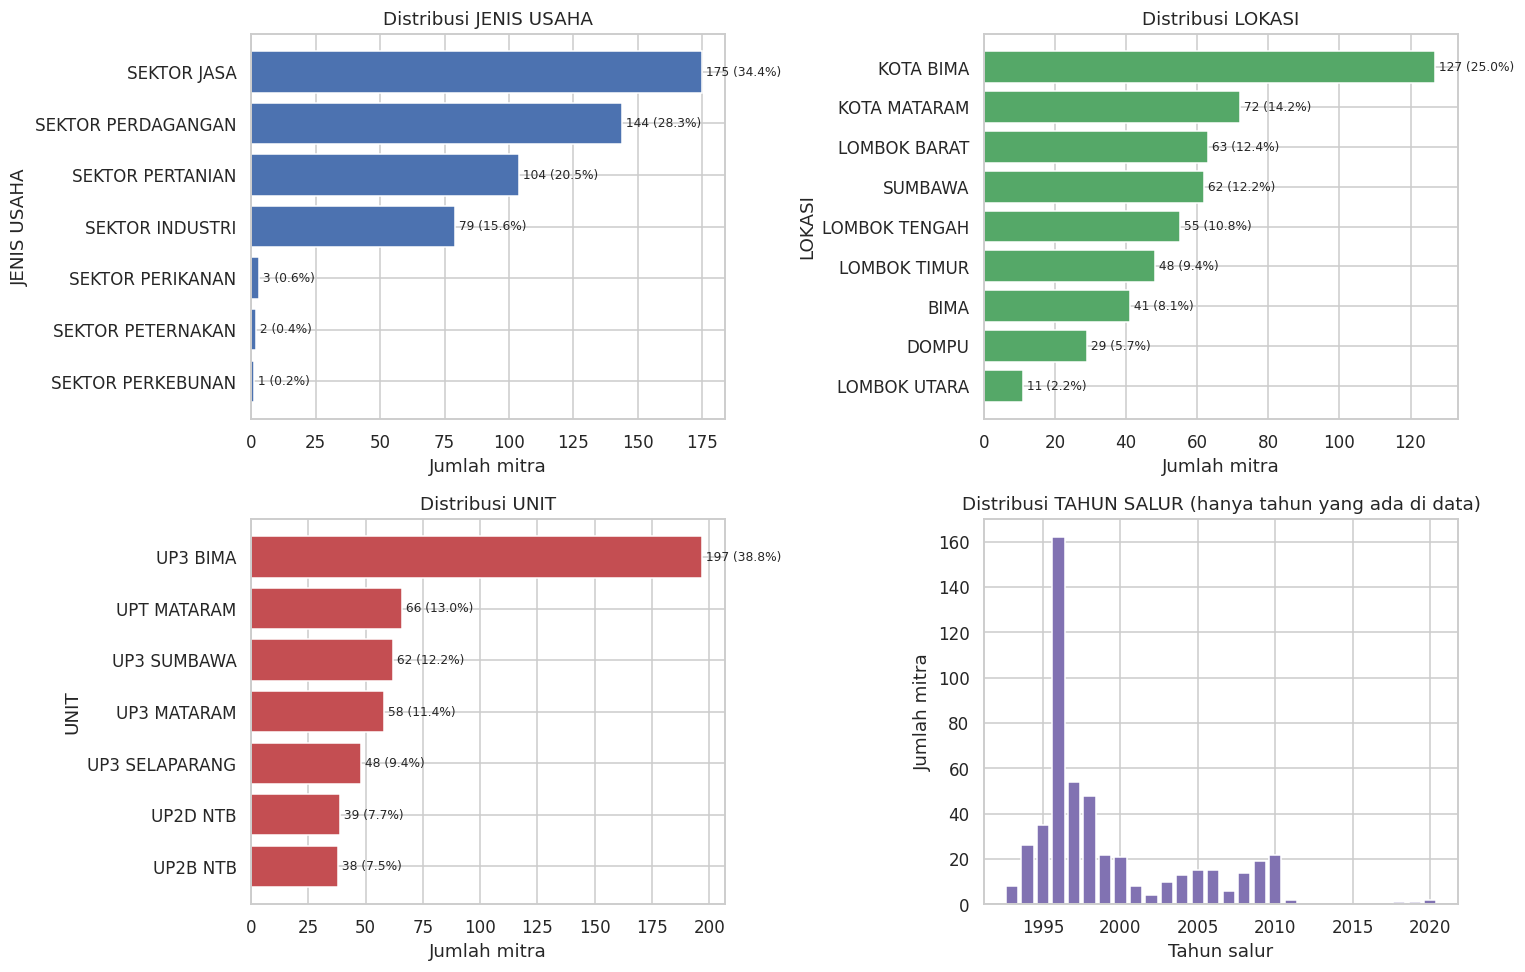

Interpretasi: tahun dengan mitra terbanyak = 1996 (162 mitra, 31.9% dari total).


In [16]:
# Grafik distribusi empat variabel setelah cleaning
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, kol, warna in zip(ax.ravel()[:3], FITUR_CLUSTER, ["#4C72B0", "#55A868", "#C44E52"]):
    t = tabel_frekuensi(df_clean[kol].astype(str))
    a.barh(t.index[::-1], t["jumlah"][::-1], color=warna)
    for y, (j, p) in enumerate(zip(t["jumlah"][::-1], t["persen"][::-1])): a.text(j, y, f" {j} ({p}%)", va="center", fontsize=8)
    a.set_title(f"Distribusi {kol}"); a.set_xlabel("Jumlah mitra"); a.set_ylabel(kol)
t_th = df_clean["TAHUN SALUR"].value_counts().sort_index()
ax[1, 1].bar(t_th.index, t_th.values, color="#8172B2")
ax[1, 1].set_title("Distribusi TAHUN SALUR (hanya tahun yang ada di data)"); ax[1, 1].set_xlabel("Tahun salur"); ax[1, 1].set_ylabel("Jumlah mitra")
plt.tight_layout(); plt.show()
puncak = t_th.idxmax()
print(f"Interpretasi: tahun dengan mitra terbanyak = {puncak} ({t_th.max()} mitra, {t_th.max()/len(df_clean)*100:.1f}% dari total).")

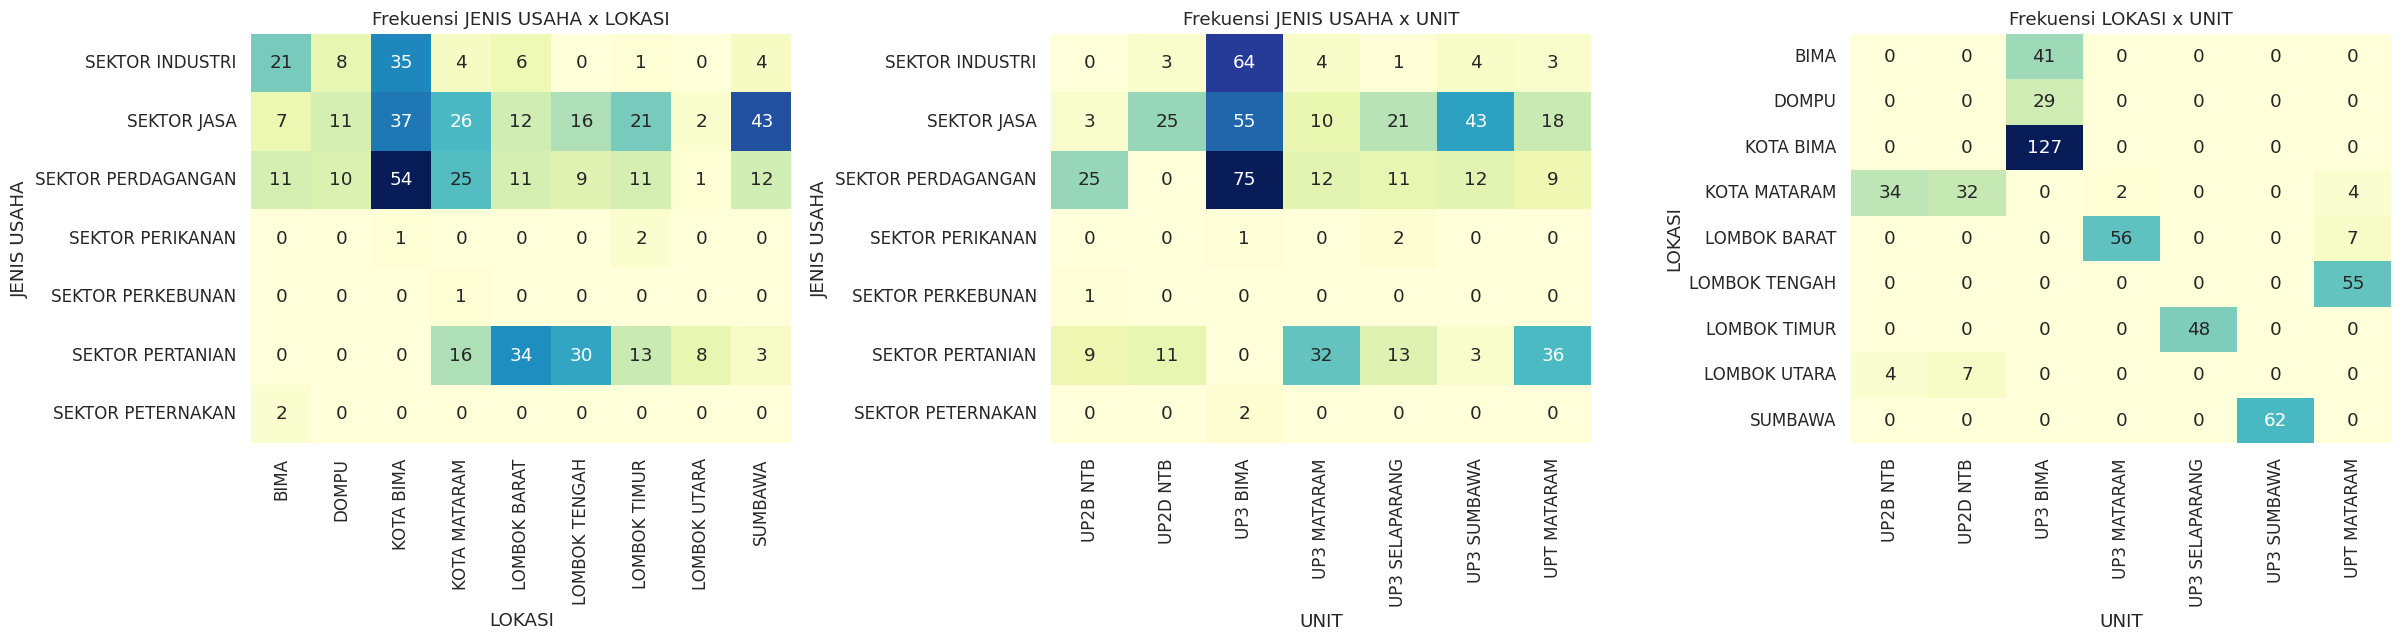

Jumlah UNIT berbeda yang melayani tiap LOKASI:


LOKASI,BIMA,DOMPU,KOTA BIMA,KOTA MATARAM,LOMBOK BARAT,LOMBOK TENGAH,LOMBOK TIMUR,LOMBOK UTARA,SUMBAWA
n_unit,1,1,1,4,2,1,1,2,1


Interpretasi: LOKASI yang hanya dilayani satu UNIT menunjukkan hubungan wilayah-unit yang sangat kuat (diukur formal di Bagian 6).


In [17]:
# Hubungan antarvariabel kategorikal: crosstab + heatmap frekuensi (JENIS-LOKASI, JENIS-UNIT, LOKASI-UNIT)
pasangan = [("JENIS USAHA", "LOKASI"), ("JENIS USAHA", "UNIT"), ("LOKASI", "UNIT")]
fig, ax = plt.subplots(1, 3, figsize=(22, 6))
for a, (p, q) in zip(ax, pasangan):
    ct = pd.crosstab(df_clean[p].astype(str), df_clean[q].astype(str))
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=a)
    a.set_title(f"Frekuensi {p} x {q}"); a.set_xlabel(q); a.set_ylabel(p)
plt.tight_layout(); plt.show()
ct_lu = pd.crosstab(df_clean["LOKASI"].astype(str), df_clean["UNIT"].astype(str))
n_unit_per_lokasi = (ct_lu > 0).sum(axis=1)
print("Jumlah UNIT berbeda yang melayani tiap LOKASI:"); display(n_unit_per_lokasi.rename("n_unit").to_frame().T)
print("Interpretasi: LOKASI yang hanya dilayani satu UNIT menunjukkan hubungan wilayah-unit yang sangat kuat (diukur formal di Bagian 6).")

## 6. Feature Selection
**Tujuan:** menetapkan fitur untuk dua jalur analisis berdasarkan tujuan penelitian, bukan algoritma seleksi fitur otomatis.

- **Tren:** `TAHUN SALUR`, `JENIS USAHA`, `LOKASI`, `UNIT` (ditetapkan oleh tujuan analisis).
- **K-Modes:** `JENIS USAHA`, `LOKASI`, `UNIT`. Dievaluasi: kardinalitas, kategori jarang, dominasi, dan asosiasi antarfitur (Cramér's V bias-corrected).

Fitur tidak dibuang hanya karena distribusinya tidak seimbang.

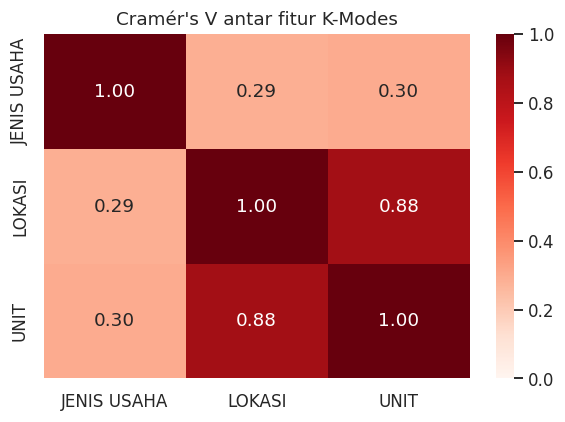

,n_kategori,persen_kategori_terbesar,n_kategori_<5%,n_kategori_<1%,entropi_ternormalisasi
JENIS USAHA,7,34.4,3,3,0.72
LOKASI,9,25.0,1,0,0.93
UNIT,7,38.8,0,0,0.90


Profil (kombinasi 3 fitur) yang benar-benar muncul: 45 dari 441 kombinasi teoretis.
V(JENIS USAHA, LOKASI) = 0.29
V(JENIS USAHA, UNIT) = 0.30
V(LOKASI, UNIT) = 0.88  -> ASOSIASI KUAT: potensi redundansi


In [18]:
# Cramér's V dengan koreksi bias (Bergsma, 2013): ukuran asosiasi 0..1 untuk dua variabel kategorikal
def cramers_v(x, y):
    ct = pd.crosstab(x, y); n = ct.values.sum()
    chi2 = chi2_contingency(ct, correction=False)[0]
    phi2 = chi2 / n
    r, k = ct.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(kc - 1, rc - 1))

V = pd.DataFrame(index=FITUR_CLUSTER, columns=FITUR_CLUSTER, dtype=float)
for a_, b_ in itertools.product(FITUR_CLUSTER, FITUR_CLUSTER):
    V.loc[a_, b_] = 1.0 if a_ == b_ else cramers_v(df_clean[a_].astype(str), df_clean[b_].astype(str))
plt.figure(figsize=(5.5, 4)); sns.heatmap(V, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Cramér's V antar fitur K-Modes"); plt.tight_layout(); plt.show()

# Kardinalitas, kategori jarang, dominasi (entropi ternormalisasi: 1 = merata, mendekati 0 = didominasi satu kategori)
def entropi_norm(s):
    p = s.value_counts(normalize=True).values
    return float(-(p * np.log(p)).sum() / np.log(len(p))) if len(p) > 1 else 0.0
kard = pd.DataFrame({
    "n_kategori": [df_clean[c].nunique() for c in FITUR_CLUSTER],
    "persen_kategori_terbesar": [round(df_clean[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in FITUR_CLUSTER],
    "n_kategori_<5%": [int((df_clean[c].value_counts(normalize=True) < 0.05).sum()) for c in FITUR_CLUSTER],
    "n_kategori_<1%": [int((df_clean[c].value_counts(normalize=True) < 0.01).sum()) for c in FITUR_CLUSTER],
    "entropi_ternormalisasi": [round(entropi_norm(df_clean[c]), 2) for c in FITUR_CLUSTER],
}, index=FITUR_CLUSTER)
display(kard)

n_profil_unik = df_clean[FITUR_CLUSTER].drop_duplicates().shape[0]
n_maks_kombinasi = int(np.prod([df_clean[c].nunique() for c in FITUR_CLUSTER]))
print(f"Profil (kombinasi 3 fitur) yang benar-benar muncul: {n_profil_unik} dari {n_maks_kombinasi} kombinasi teoretis.")
for (a_, b_) in itertools.combinations(FITUR_CLUSTER, 2):
    v = V.loc[a_, b_]
    print(f"V({a_}, {b_}) = {v:.2f}" + ("  -> ASOSIASI KUAT: potensi redundansi" if v >= 0.7 else ""))

**Keputusan metodologis (Feature Selection K-Modes)**
1. Ketiga fitur dipertahankan karena masing-masing menjawab tujuan segmentasi (sektor, wilayah, unit pelaksana).
2. Jika `LOKASI` dan `UNIT` berasosiasi sangat kuat (lihat nilai V di atas), K-Modes secara efektif memberi bobot geografi lebih besar daripada `JENIS USAHA`: dua dari tiga fitur membawa informasi wilayah yang hampir sama. Ini **keterbatasan** yang harus ditulis di laporan, dan interpretasi cluster harus memperhatikannya.
3. Tidak dilakukan eksperimen pengurangan fitur dalam notebook ini. Jika ingin membandingkan model 2-fitur (mis. tanpa `UNIT`), lakukan hanya setelah disetujui pembimbing dan laporkan sebagai analisis sensitivitas, bukan model utama.
4. Kategori jarang pada `JENIS USAHA` tidak digabung. Konsekuensinya: kategori itu hampir pasti tidak menjadi modus cluster mana pun, sehingga tidak muncul sebagai ciri cluster. Ini dilaporkan, bukan disembunyikan.

In [19]:
# Pembuatan dataset terpisah untuk dua jalur analisis
df_trend = df_clean[FITUR_TREND].copy()
df_trend["JENIS USAHA"] = df_trend["JENIS USAHA"].astype(str); df_trend["LOKASI"] = df_trend["LOKASI"].astype(str); df_trend["UNIT"] = df_trend["UNIT"].astype(str)
df_cluster = df_clean[FITUR_CLUSTER].copy().astype(str)          # hanya 3 fitur; tanpa identitas, tanpa tahun

assert list(df_cluster.columns) == FITUR_CLUSTER
assert not {"NO ID", "NO URUT", "NAMA USAHA", "TAHUN SALUR"} & set(df_cluster.columns)
print("df_trend  :", df_trend.shape, df_trend.columns.tolist())
print("df_cluster:", df_cluster.shape, df_cluster.columns.tolist())

df_trend  : (508, 4) ['TAHUN SALUR', 'JENIS USAHA', 'LOKASI', 'UNIT']
df_cluster: (508, 3) ['JENIS USAHA', 'LOKASI', 'UNIT']


## 7. Analisis Tren Mitra Binaan
**Tujuan:** menggambarkan perkembangan dan distribusi mitra menurut tahun penyaluran, jenis usaha, lokasi, dan unit (`df_trend`).

**Kehati-hatian temporal**
- Tahun yang tidak muncul **tidak dianggap nol penyaluran**; ketiadaan data bisa berarti program tidak menyalurkan, atau data tidak tercatat di database ini. Dibedakan pada grafik (tanpa batang, bukan batang nol).
- Perbandingan komposisi antarperiode memakai periode tetap (bin) sebagai alat ringkas, dan jumlah mitra per periode ditampilkan; periode dengan jumlah kecil tidak diinterpretasi sebagai kenaikan/penurunan.

TAHUN SALUR,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2018,2019,2020
jumlah_mitra,8.0,26.0,35.0,162.0,54.0,48.0,22.0,21.0,8.0,4.0,10.0,13.0,15.0,15.0,6.0,14.0,19.0,22.0,2.0,1.0,1.0,2.0
persen,1.6,5.1,6.9,31.9,10.6,9.4,4.3,4.1,1.6,0.8,2.0,2.6,3.0,3.0,1.2,2.8,3.7,4.3,0.4,0.2,0.2,0.4
kumulatif,8.0,34.0,69.0,231.0,285.0,333.0,355.0,376.0,384.0,388.0,398.0,411.0,426.0,441.0,447.0,461.0,480.0,502.0,504.0,505.0,506.0,508.0


Tahun tanpa observasi dalam rentang: [2012, 2013, 2014, 2015, 2016, 2017]


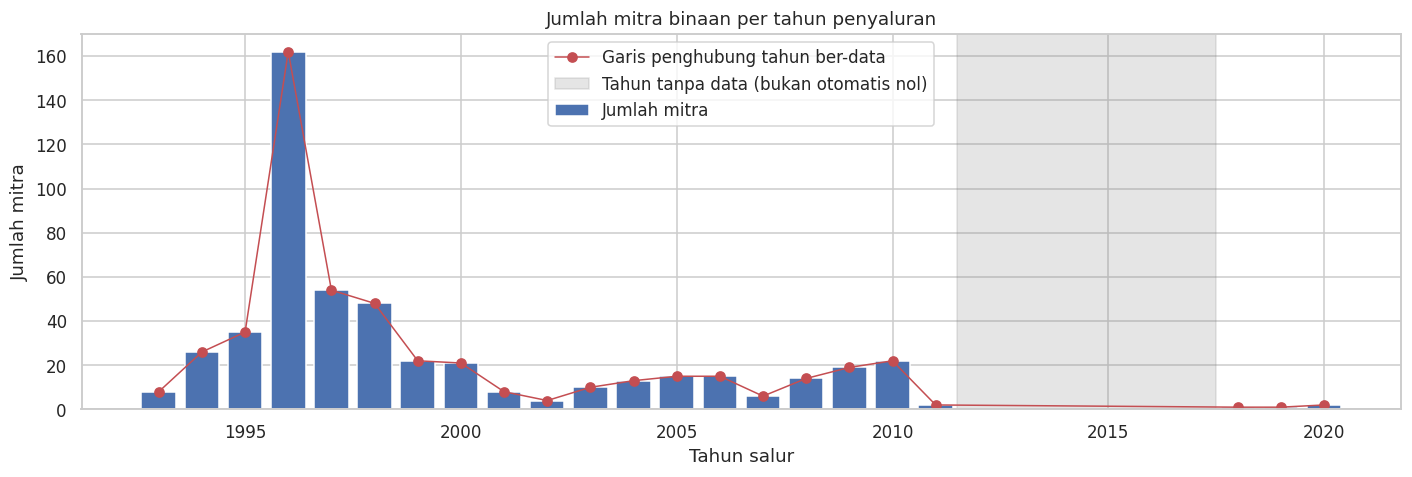

Tiga tahun terbanyak: {1996: 162, 1997: 54, 1998: 48} -> 52.0% dari seluruh mitra


In [20]:
# A. Tren jumlah mitra per tahun penyaluran
tren_tahun = df_trend["TAHUN SALUR"].value_counts().sort_index().rename("jumlah_mitra").to_frame()
tren_tahun["persen"] = (tren_tahun["jumlah_mitra"] / len(df_trend) * 100).round(1)
tren_tahun["kumulatif"] = tren_tahun["jumlah_mitra"].cumsum()
display(tren_tahun.T)

th_min, th_max = int(tren_tahun.index.min()), int(tren_tahun.index.max())
tahun_tanpa_data = sorted(set(range(th_min, th_max + 1)) - set(tren_tahun.index))
print("Tahun tanpa observasi dalam rentang:", tahun_tanpa_data if tahun_tanpa_data else "tidak ada")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(tren_tahun.index, tren_tahun["jumlah_mitra"], color="#4C72B0", label="Jumlah mitra")
ax.plot(tren_tahun.index, tren_tahun["jumlah_mitra"], color="#C44E52", marker="o", lw=1, label="Garis penghubung tahun ber-data")
# Tandai rentang tahun tanpa data (bukan nol)
if tahun_tanpa_data:
    ax.axvspan(min(tahun_tanpa_data) - 0.5, max(tahun_tanpa_data) + 0.5, color="grey", alpha=0.2, label="Tahun tanpa data (bukan otomatis nol)")
ax.set_title("Jumlah mitra binaan per tahun penyaluran"); ax.set_xlabel("Tahun salur"); ax.set_ylabel("Jumlah mitra"); ax.legend()
plt.tight_layout(); plt.show()
n_terbesar = tren_tahun["jumlah_mitra"].nlargest(3)
print("Tiga tahun terbanyak:", {int(k): int(v) for k, v in n_terbesar.items()}, f"-> {n_terbesar.sum()/len(df_trend)*100:.1f}% dari seluruh mitra")

In [21]:
# Periode tetap untuk ringkasan komposisi (alat bantu deskriptif; bukan fitur model)
batas = [th_min - 1, 1996, 2000, 2005, 2011, th_max]
label_periode = [f"{batas[i]+1}-{batas[i+1]}" for i in range(len(batas) - 1)]
df_trend["PERIODE"] = pd.cut(df_trend["TAHUN SALUR"], bins=batas, labels=label_periode)
n_per_periode = df_trend["PERIODE"].value_counts().reindex(label_periode).rename("n_mitra")
display(n_per_periode.to_frame().T)
print("Periode dengan n < 30 hanya boleh dideskripsikan, tidak ditafsirkan sebagai tren.")

# Fungsi analisis satu dimensi (jenis usaha / lokasi / unit): jumlah total, komposisi per periode, grafik
def analisis_dimensi(kol, judul):
    total = tabel_frekuensi(df_trend[kol]); print(f"\n##### {judul}: jumlah mitra per kategori"); display(total)
    ct = pd.crosstab(df_trend["PERIODE"], df_trend[kol])
    persen = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
    persen.insert(0, "n_periode", ct.sum(axis=1))
    print(f"Komposisi {judul} per periode (% baris):"); display(persen)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    thn_pivot = pd.crosstab(df_trend["TAHUN SALUR"], df_trend[kol])
    thn_pivot.plot(kind="bar", stacked=True, ax=ax[0], width=0.85, colormap="tab10")
    ax[0].set_title(f"Jumlah mitra per tahun menurut {judul} (hanya tahun ber-data)"); ax[0].set_xlabel("Tahun salur"); ax[0].set_ylabel("Jumlah mitra"); ax[0].legend(title=kol, fontsize=7)
    (ct.div(ct.sum(axis=1), axis=0)).plot(kind="bar", stacked=True, ax=ax[1], colormap="tab10", width=0.8)
    ax[1].set_title(f"Komposisi {judul} per periode (proporsi)"); ax[1].set_xlabel("Periode"); ax[1].set_ylabel("Proporsi"); ax[1].legend(title=kol, fontsize=7)
    plt.setp(ax[1].get_xticklabels(), rotation=20); plt.tight_layout(); plt.show()
    return total, thn_pivot, persen

PERIODE,1993-1996,1997-2000,2001-2005,2006-2011,2012-2020
n_mitra,231,145,50,78,4


Periode dengan n < 30 hanya boleh dideskripsikan, tidak ditafsirkan sebagai tren.



##### Jenis Usaha: jumlah mitra per kategori


,jumlah,persen
JENIS USAHA,,
SEKTOR JASA,175,34.4
SEKTOR PERDAGANGAN,144,28.3
SEKTOR PERTANIAN,104,20.5
SEKTOR INDUSTRI,79,15.6
SEKTOR PERIKANAN,3,0.6
SEKTOR PETERNAKAN,2,0.4
SEKTOR PERKEBUNAN,1,0.2


Komposisi Jenis Usaha per periode (% baris):


JENIS USAHA,n_periode,SEKTOR INDUSTRI,SEKTOR JASA,SEKTOR PERDAGANGAN,SEKTOR PERIKANAN,SEKTOR PERKEBUNAN,SEKTOR PERTANIAN,SEKTOR PETERNAKAN
PERIODE,,,,,,,,
1993-1996,231,22.1,32.5,16.5,0.4,0.0,27.7,0.9
1997-2000,145,6.2,37.2,29.0,0.0,0.0,27.6,0.0
2001-2005,50,12.0,36.0,52.0,0.0,0.0,0.0,0.0
2006-2011,78,14.1,34.6,47.4,2.6,1.3,0.0,0.0
2012-2020,4,50.0,25.0,25.0,0.0,0.0,0.0,0.0


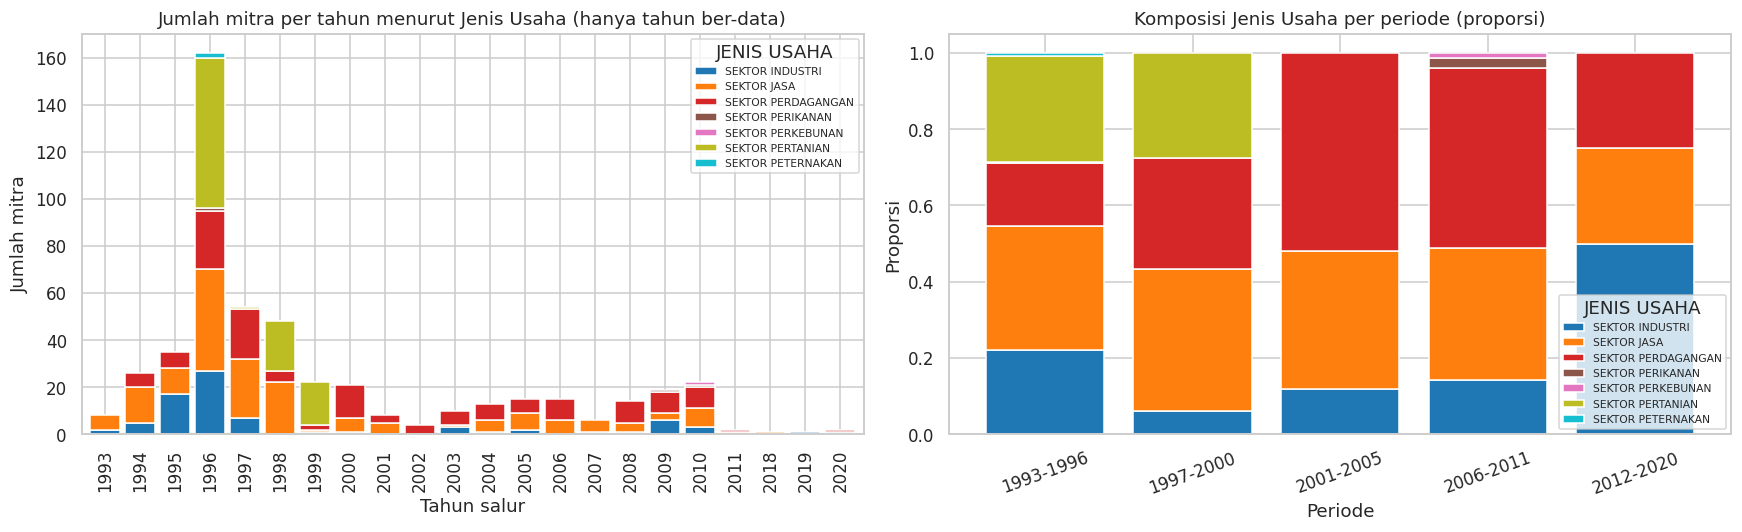

In [22]:
# B. Tren berdasarkan JENIS USAHA
tren_jenis_total, tren_jenis_tahun, tren_jenis_periode = analisis_dimensi("JENIS USAHA", "Jenis Usaha")


##### Lokasi: jumlah mitra per kategori


,jumlah,persen
LOKASI,,
KOTA BIMA,127,25.0
KOTA MATARAM,72,14.2
LOMBOK BARAT,63,12.4
SUMBAWA,62,12.2
LOMBOK TENGAH,55,10.8
LOMBOK TIMUR,48,9.4
BIMA,41,8.1
DOMPU,29,5.7
LOMBOK UTARA,11,2.2


Komposisi Lokasi per periode (% baris):


LOKASI,n_periode,BIMA,DOMPU,KOTA BIMA,KOTA MATARAM,LOMBOK BARAT,LOMBOK TENGAH,LOMBOK TIMUR,LOMBOK UTARA,SUMBAWA
PERIODE,,,,,,,,,,
1993-1996,231,10.8,8.2,28.6,3.9,10.0,14.3,10.8,1.3,12.1
1997-2000,145,9.0,5.5,19.3,20.7,14.5,8.3,3.4,4.8,14.5
2001-2005,50,2.0,4.0,18.0,22.0,24.0,10.0,20.0,0.0,0.0
2006-2011,78,2.6,0.0,30.8,25.6,7.7,5.1,10.3,1.3,16.7
2012-2020,4,0.0,0.0,0.0,50.0,25.0,25.0,0.0,0.0,0.0


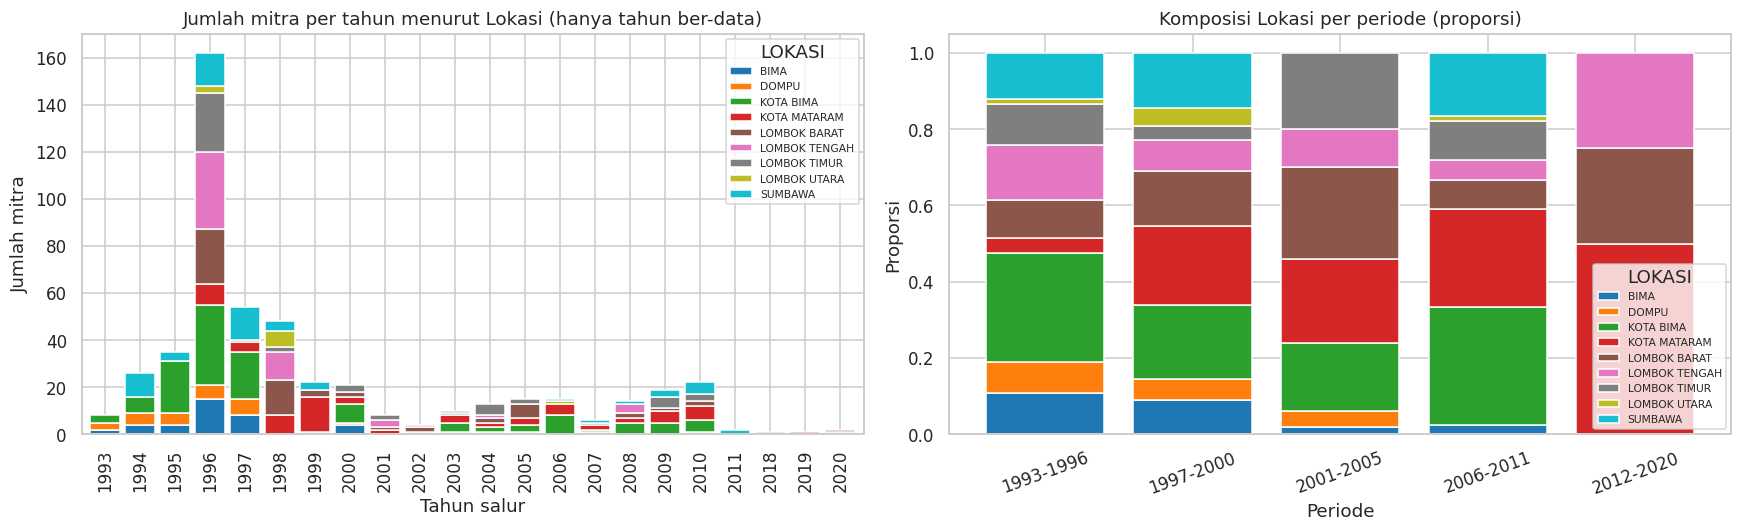

In [23]:
# C. Tren berdasarkan LOKASI
tren_lokasi_total, tren_lokasi_tahun, tren_lokasi_periode = analisis_dimensi("LOKASI", "Lokasi")


##### Unit: jumlah mitra per kategori


,jumlah,persen
UNIT,,
UP3 BIMA,197,38.8
UPT MATARAM,66,13.0
UP3 SUMBAWA,62,12.2
UP3 MATARAM,58,11.4
UP3 SELAPARANG,48,9.4
UP2D NTB,39,7.7
UP2B NTB,38,7.5


Komposisi Unit per periode (% baris):


UNIT,n_periode,UP2B NTB,UP2D NTB,UP3 BIMA,UP3 MATARAM,UP3 SELAPARANG,UP3 SUMBAWA,UPT MATARAM
PERIODE,,,,,,,,
1993-1996,231,2.6,2.6,47.6,9.5,10.8,12.1,14.7
1997-2000,145,9.7,13.1,33.8,13.1,3.4,14.5,12.4
2001-2005,50,14.0,8.0,24.0,24.0,20.0,0.0,10.0
2006-2011,78,14.1,12.8,33.3,3.8,10.3,16.7,9.0
2012-2020,4,0.0,0.0,0.0,50.0,0.0,0.0,50.0


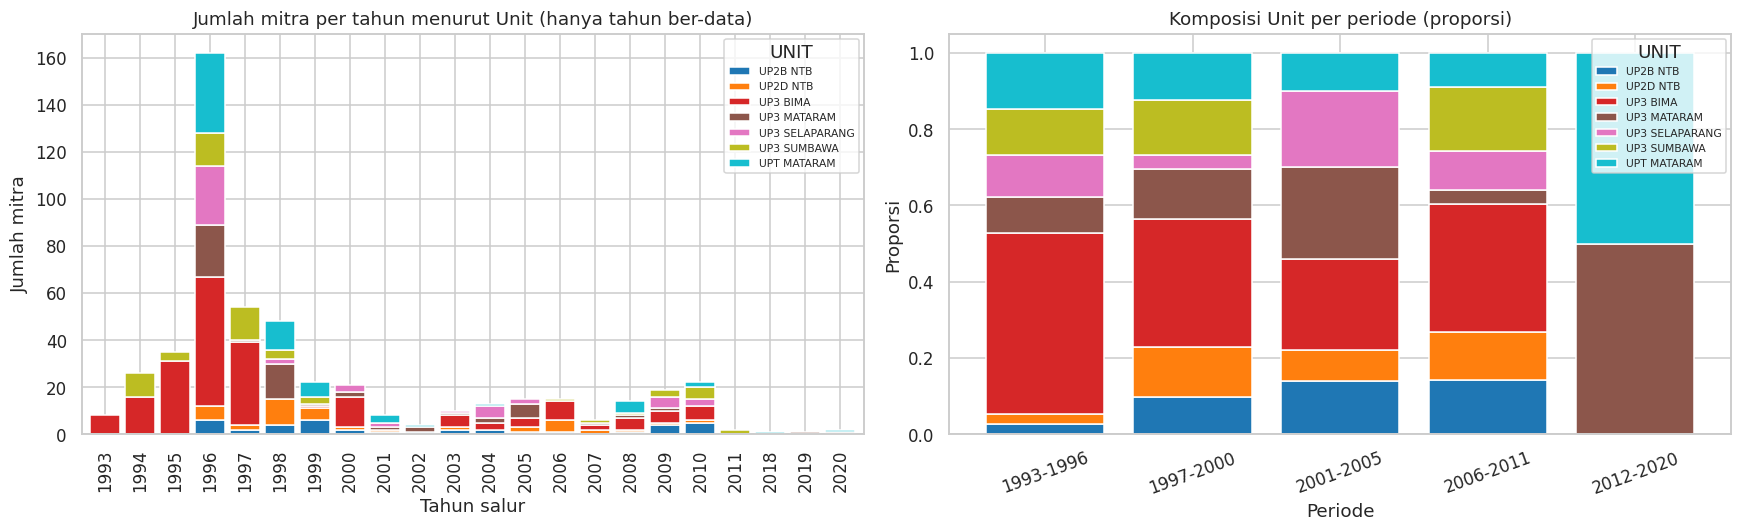

In [24]:
# D. Tren berdasarkan UNIT
tren_unit_total, tren_unit_tahun, tren_unit_periode = analisis_dimensi("UNIT", "Unit")

**Interpretasi dan batasan analisis tren** (tulis dari output di atas): (1) tahun/periode konsentrasi penyaluran, (2) kategori dominan tiap dimensi, (3) perubahan komposisi hanya pada periode ber-n memadai, (4) tahun tanpa data tidak ditafsirkan sebagai nol. Tren ini menggambarkan **mitra yang tercatat di database**, bukan kinerja program secara keseluruhan.

## 8. Persiapan Data untuk K-Modes
**Tujuan:** menyiapkan data kategorikal untuk pemodelan.

- Input model: `df_cluster` bertipe teks kategori (K-Modes menghitung kecocokan kategori; tidak ada scaling, tidak ada One-Hot).
- Untuk **evaluasi** Silhouette saja dibuat representasi ordinal + matriks jarak Hamming (= simple matching dissimilarity: proporsi fitur yang kategorinya berbeda). Representasi ordinal **tidak** dipakai sebagai input model.

In [25]:
# Validasi akhir sebelum pemodelan
print("Dimensi data final:", df_cluster.shape)
print("Missing value:", int(df_cluster.isna().sum().sum()))
print("Tipe:", df_cluster.dtypes.astype(str).unique().tolist())
for kol in FITUR_CLUSTER: print(f"{kol}: {sorted(df_cluster[kol].unique())}")
X = df_cluster.to_numpy()      # input utama K-Modes (array kategori teks)

# Matriks jarak simple matching untuk evaluasi Silhouette (dihitung sekali; identik di semua eksperimen)
X_ord = OrdinalEncoder().fit_transform(df_cluster)
D = pairwise_distances(X_ord, metric="hamming")
nilai_D = np.unique(np.round(D, 6))
print("Nilai unik jarak:", nilai_D, "(harus kelipatan 1/3 untuk 3 fitur)")
assert set(nilai_D).issubset({0, round(1/3, 6), round(2/3, 6), 1.0})

Dimensi data final: (508, 3)
Missing value: 0
Tipe: ['object']
JENIS USAHA: ['SEKTOR INDUSTRI', 'SEKTOR JASA', 'SEKTOR PERDAGANGAN', 'SEKTOR PERIKANAN', 'SEKTOR PERKEBUNAN', 'SEKTOR PERTANIAN', 'SEKTOR PETERNAKAN']
LOKASI: ['BIMA', 'DOMPU', 'KOTA BIMA', 'KOTA MATARAM', 'LOMBOK BARAT', 'LOMBOK TENGAH', 'LOMBOK TIMUR', 'LOMBOK UTARA', 'SUMBAWA']
UNIT: ['UP2B NTB', 'UP2D NTB', 'UP3 BIMA', 'UP3 MATARAM', 'UP3 SELAPARANG', 'UP3 SUMBAWA', 'UPT MATARAM']
Nilai unik jarak: [0.       0.333333 0.666667 1.      ] (harus kelipatan 1/3 untuk 3 fitur)


## 9. Eksperimen Pemodelan K-Modes
**Tujuan:** mencari konfigurasi terbaik secara terstruktur dan dapat direproduksi.

### Aturan keputusan (ditetapkan SEBELUM eksperimen dijalankan)
Konfigurasi akhir dipilih dengan urutan berikut, bukan dengan melihat hasil lalu memilih yang disukai:
1. **Konvergen**: seluruh percobaan (semua seed) pada kombinasi (K, init) berhenti sebelum `max_iter`.
2. **Tidak ada cluster kosong** dan **cluster terkecil ≥ `MIN_SHARE`** dari total mitra pada seluruh percobaan.
3. **Stabil**: rata-rata ARI antar-seed ≥ `MIN_ARI`.
4. Dari yang lolos, urutkan menurut **rata-rata Silhouette** (simple matching) tertinggi (Silhouette adalah evaluasi utama).
5. Kombinasi dengan Silhouette dalam selisih `TIE_TOL` dari yang tertinggi dianggap **berdekatan**: ditampilkan dengan kelebihan/kekurangannya; bila tetap perlu dipilih satu, dipakai K terkecil (parsimoni), lalu urutan init pada daftar. Override manual hanya lewat `FINAL_OVERRIDE` dan wajib disertai alasan tertulis.
6. Cost **tidak** dipakai sendiri untuk memilih (cost turun mekanis bila K naik); dipakai sebagai pembanding dan untuk memilih seed representatif.

Seed **tidak** dipilih sebagai "terbaik"; seed hanya dipakai untuk mengukur stabilitas. Seed representatif untuk label akhir = partisi **medoid**: seed dengan rata-rata ARI tertinggi terhadap seed lain pada konfigurasi terpilih (bila sama, dipilih cost lebih rendah). Dengan begitu label akhir adalah partisi yang paling 'tipikal', bukan seed yang dianggap terbaik.

In [26]:
# Parameter eksperimen dan ambang aturan keputusan (tetap, dicatat untuk laporan)
K_RANGE = list(range(2, 11))
INITS = {"Huang": "Huang", "Cao": "Cao", "Random": "random"}     # nama tampilan -> argumen kmodes
SEEDS = [0, 21, 42, 84, 123, 2026]
N_INIT = 10          # jumlah inisialisasi per percobaan (Cao deterministik -> otomatis 1)
MAX_ITER = 100       # batas iterasi
MIN_SHARE, MIN_ARI, TIE_TOL = 0.05, 0.80, 0.01
FINAL_OVERRIDE = None   # contoh override: ("Huang", 4) -> wajib dijelaskan alasannya di laporan

print(f"Jumlah profil unik = {n_profil_unik}; rentang K = {K_RANGE[0]}-{K_RANGE[-1]}.")
print(f"Cluster terkecil yang diterima = {MIN_SHARE*100:.0f}% (~{int(np.ceil(MIN_SHARE*len(X)))} mitra).")

Jumlah profil unik = 45; rentang K = 2-10.
Cluster terkecil yang diterima = 5% (~26 mitra).


In [27]:
# Fungsi satu percobaan: K-Modes dijalankan pada data yang SAMA, lalu dihitung metrik evaluasi
def jalankan_kmodes(k, init_nama, seed, n_init=N_INIT, max_iter=MAX_ITER, data=X):
    n_init_eff = 1 if init_nama == "Cao" else n_init           # Cao deterministik: n_init>1 tidak ada gunanya
    km = KModes(n_clusters=k, init=INITS[init_nama], n_init=n_init_eff, max_iter=max_iter, random_state=seed, verbose=0)
    label = km.fit_predict(data)
    ukuran = np.bincount(label, minlength=k)
    n_aktif = int((ukuran > 0).sum())
    n_iter = getattr(km, "n_iter_", np.nan)
    sil = silhouette_score(D, label, metric="precomputed") if n_aktif >= 2 else np.nan
    return km, label, {
        "k": k, "init": init_nama, "seed": seed, "n_init_efektif": n_init_eff, "max_iter": max_iter,
        "n_iter": n_iter, "konvergen": bool(n_iter < max_iter) if not np.isnan(n_iter) else np.nan,
        "cost": float(km.cost_), "silhouette": float(sil), "n_cluster_aktif": n_aktif,
        "ukuran_cluster": sorted(ukuran.tolist(), reverse=True), "share_terkecil": float(ukuran.min() / len(label)),
    }

# Eksperimen utama: K x metode inisialisasi x seed (semua percobaan dicatat)
hasil, simpan_label = [], {}
t0 = time.time()
for init_nama, k, seed in itertools.product(INITS, K_RANGE, SEEDS):
    km, label, baris = jalankan_kmodes(k, init_nama, seed)
    hasil.append(baris); simpan_label[(init_nama, k, seed)] = label
df_exp = pd.DataFrame(hasil)
print(f"{len(df_exp)} percobaan selesai dalam {time.time()-t0:.1f} detik")
display(df_exp.head(10))

162 percobaan selesai dalam 68.2 detik


,k,init,seed,n_init_efektif,max_iter,n_iter,konvergen,cost,silhouette,n_cluster_aktif,ukuran_cluster,share_terkecil
0,2,Huang,0,10,100,2,True,812.0,0.258839,2,"[305, 203]",0.399606
1,2,Huang,21,10,100,1,True,824.0,0.229701,2,"[369, 139]",0.273622
2,2,Huang,42,10,100,2,True,818.0,0.269785,2,"[376, 132]",0.259843
3,2,Huang,84,10,100,1,True,818.0,0.269785,2,"[376, 132]",0.259843
4,2,Huang,123,10,100,1,True,812.0,0.271485,2,"[375, 133]",0.261811
5,2,Huang,2026,10,100,1,True,812.0,0.271485,2,"[375, 133]",0.261811
6,3,Huang,0,10,100,2,True,626.0,0.338325,3,"[224, 145, 139]",0.273622
7,3,Huang,21,10,100,2,True,714.0,0.311180,3,"[350, 99, 59]",0.116142
8,3,Huang,42,10,100,2,True,629.0,0.333211,3,"[227, 142, 139]",0.273622
9,3,Huang,84,10,100,2,True,626.0,0.352857,3,"[250, 129, 129]",0.253937


**Istilah penting**
- **K**: jumlah cluster yang diminta.
- **Init (inisialisasi)**: cara memilih "pusat" awal tiap cluster. *Random* = pilih mitra acak. *Huang* = pilih secara acak tetapi berdasarkan kategori yang sering muncul. *Cao* = pilih pusat yang berada di area padat dan saling berjauhan; hasilnya selalu sama (deterministik).
- **Seed (random_state)**: "nomor kunci" pengacak. Seed sama = hasil sama, seed beda = pusat awal beda. Seed tidak dicari yang terbaik, hanya dipakai untuk melihat apakah hasil stabil.
- **n_init**: berapa kali K-Modes diulang dari pusat awal berbeda dalam satu percobaan, lalu diambil yang cost-nya terkecil.
- **max_iter**: batas putaran ulang. Bila berhenti sebelum batas, berarti sudah konvergen.
- **Mode (pusat cluster)**: kategori paling sering di tiap fitur. Pada data kategorikal, mode adalah padanan rata-rata.
- **Cost**: total ketidakcocokan semua mitra terhadap mode clusternya. Makin kecil makin rapat, tetapi otomatis turun saat K naik.

In [28]:
# Cek determinisme: berapa kombinasi (init, K) yang hasilnya identik di semua seed? (Cao seharusnya selalu identik)
def ari_antar_seed(init_nama, k):
    lab = [simpan_label[(init_nama, k, s)] for s in SEEDS]
    nilai = [adjusted_rand_score(a, b) for a, b in itertools.combinations(lab, 2)]
    return float(np.mean(nilai)), float(np.min(nilai))

stab = pd.DataFrame([{"init": i, "k": k, **dict(zip(["ari_rata", "ari_min"], ari_antar_seed(i, k)))} for i in INITS for k in K_RANGE])
print("Rata-rata ARI antar-seed = 1.00 berarti seed tidak mengubah partisi pada kombinasi tersebut.")
display(stab.pivot(index="k", columns="init", values="ari_rata").round(3))

Rata-rata ARI antar-seed = 1.00 berarti seed tidak mengubah partisi pada kombinasi tersebut.


init,Cao,Huang,Random
k,,,
2,1.0,0.401,0.526
3,1.0,0.583,0.868
4,1.0,0.584,0.627
5,1.0,0.494,0.593
6,1.0,0.514,0.613
7,1.0,0.562,0.610
8,1.0,0.616,0.651
9,1.0,0.698,0.673
10,1.0,0.793,0.812


**Apa itu ARI (Adjusted Rand Index)?** Ukuran seberapa mirip dua hasil pengelompokan pada mitra yang sama, tidak peduli nomor/nama cluster-nya.
- 1 = identik; sekitar 0 = sama dengan kebetulan; negatif = lebih buruk dari kebetulan.
- Dipakai untuk menguji stabilitas: jalankan dengan seed berbeda, lalu cek apakah pengelompokan tetap mirip. ARI antar-seed ≥ 0,80 dianggap stabil.
- ARI = 1 pada Cao bukan berarti Cao bagus, hanya karena Cao selalu menghasilkan hal yang sama.

## 10. Evaluasi Cluster
Ukuran evaluasi: **Silhouette** (jarak simple matching), **cost K-Modes**, **stabilitas (ARI)**, dan **distribusi ukuran cluster**. ARI membandingkan partisi antar-percobaan pada observasi yang sama dan tidak terpengaruh urutan nomor cluster.

In [29]:
# Agregasi per (init, K): rata-rata/simpangan metrik, laju konvergensi, ukuran cluster terkecil, stabilitas ARI
agg = df_exp.groupby(["init", "k"]).agg(
    sil_mean=("silhouette", "mean"), sil_std=("silhouette", "std"),
    cost_mean=("cost", "mean"), cost_min=("cost", "min"), cost_std=("cost", "std"),
    iter_mean=("n_iter", "mean"), konv_rate=("konvergen", "mean"),
    share_terkecil_min=("share_terkecil", "min"), n_aktif_min=("n_cluster_aktif", "min"),
).reset_index()
agg = agg.merge(stab, on=["init", "k"])
agg["init"] = pd.Categorical(agg["init"], categories=list(INITS), ordered=True)
agg = agg.sort_values(["init", "k"]).reset_index(drop=True)
display(agg.round(4))

,init,k,sil_mean,sil_std,cost_mean,cost_min,cost_std,iter_mean,konv_rate,share_terkecil_min,n_aktif_min,ari_rata,ari_min
0,Huang,2,0.2618,0.0165,816.0000,812.0,4.8990,1.3333,1.0,0.2598,2,0.4014,-0.0491
1,Huang,3,0.3385,0.0157,647.3333,626.0,35.7529,1.8333,1.0,0.1161,3,0.5831,0.2040
2,Huang,4,0.3792,0.0331,558.8333,537.0,13.2124,2.0000,1.0,0.0945,4,0.5841,0.4239
3,Huang,5,0.3680,0.0627,491.1667,472.0,11.8898,2.3333,1.0,0.0768,5,0.4937,0.3236
4,Huang,6,0.4293,0.0786,426.5000,400.0,19.0866,1.5000,1.0,0.0512,6,0.5137,0.3914
5,Huang,7,0.4734,0.0574,361.8333,337.0,19.8335,1.6667,1.0,0.0689,7,0.5617,0.4451
6,Huang,8,0.5296,0.0553,307.3333,280.0,31.9979,1.5000,1.0,0.0394,8,0.6156,0.4603
7,Huang,9,0.5541,0.0229,265.1667,237.0,15.3937,2.6667,1.0,0.0256,9,0.6978,0.5857
8,Huang,10,0.6049,0.0247,222.5000,202.0,15.8588,2.1667,1.0,0.0197,10,0.7926,0.7058
9,Cao,2,0.1910,0.0000,862.0000,862.0,0.0000,1.0000,1.0,0.2461,2,1.0000,1.0000


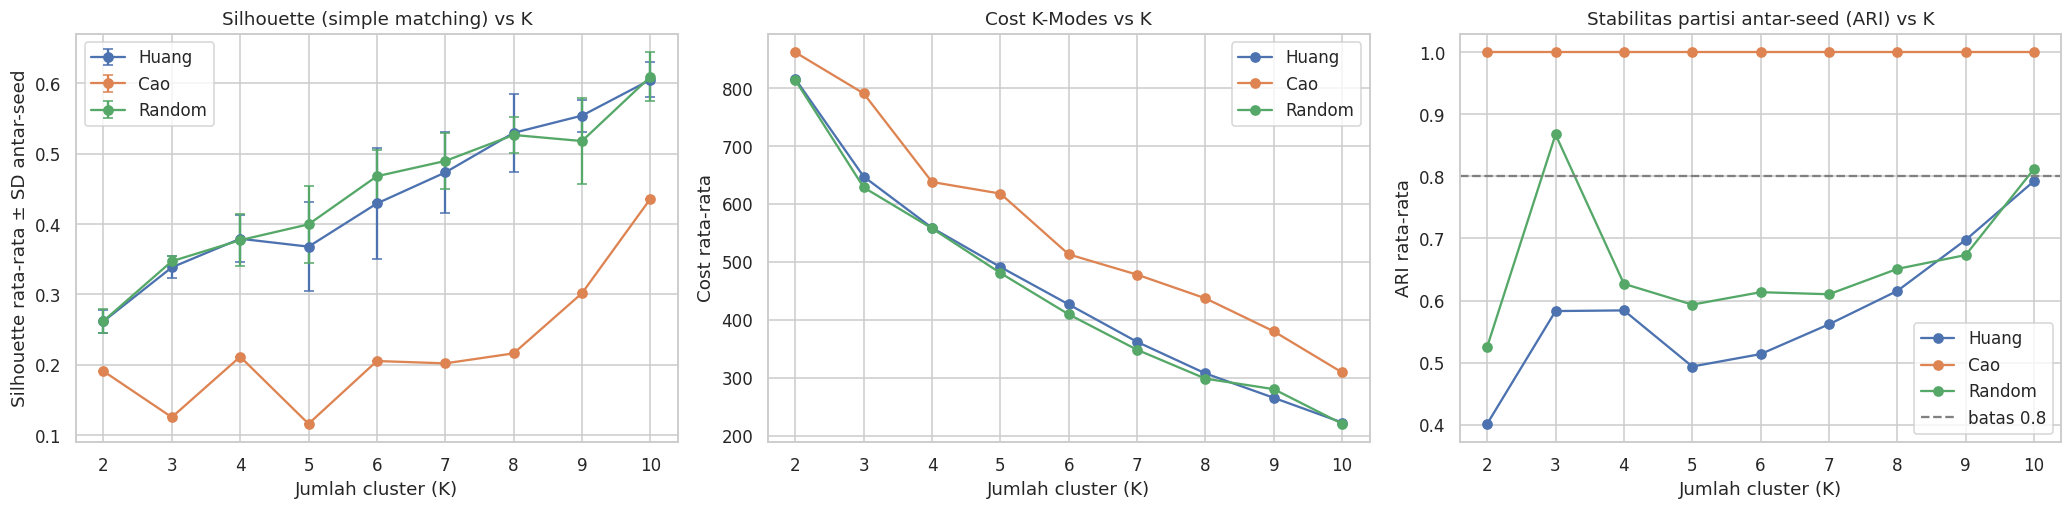

Cost selalu menurun saat K naik, sehingga bukan kriteria tunggal; titik 'siku' hanya petunjuk tambahan.


In [30]:
# Grafik evaluasi: Silhouette, cost, dan stabilitas terhadap K untuk tiap metode inisialisasi
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for init_nama in INITS:
    a_ = agg[agg["init"] == init_nama]
    ax[0].errorbar(a_["k"], a_["sil_mean"], yerr=a_["sil_std"].fillna(0), marker="o", capsize=3, label=init_nama)
    ax[1].plot(a_["k"], a_["cost_mean"], marker="o", label=init_nama)
    ax[2].plot(a_["k"], a_["ari_rata"], marker="o", label=init_nama)
ax[0].set_title("Silhouette (simple matching) vs K"); ax[0].set_ylabel("Silhouette rata-rata ± SD antar-seed")
ax[1].set_title("Cost K-Modes vs K"); ax[1].set_ylabel("Cost rata-rata")
ax[2].set_title("Stabilitas partisi antar-seed (ARI) vs K"); ax[2].set_ylabel("ARI rata-rata"); ax[2].axhline(MIN_ARI, ls="--", c="grey", label=f"batas {MIN_ARI}")
for a in ax: a.set_xlabel("Jumlah cluster (K)"); a.legend()
plt.tight_layout(); plt.show()
print("Cost selalu menurun saat K naik, sehingga bukan kriteria tunggal; titik 'siku' hanya petunjuk tambahan.")

In [31]:
# Kesepakatan antar metode inisialisasi (ARI antar partisi cost terendah masing-masing metode, per K)
def label_wakil(init_nama, k):
    sub = df_exp[(df_exp["init"] == init_nama) & (df_exp["k"] == k)]
    return simpan_label[(init_nama, k, int(sub.loc[sub["cost"].idxmin(), "seed"]))]
antar_init = pd.DataFrame([{
    "k": k, **{f"{a_}-{b_}": adjusted_rand_score(label_wakil(a_, k), label_wakil(b_, k)) for a_, b_ in itertools.combinations(INITS, 2)}
} for k in K_RANGE]).set_index("k").round(3)
display(antar_init)

,Huang-Cao,Huang-Random,Cao-Random
k,,,
2,0.474,0.520,0.190
3,0.048,0.958,0.047
4,0.193,0.621,0.202
5,0.196,0.710,0.155
6,0.372,0.512,0.172
7,0.323,0.860,0.287
8,0.384,0.673,0.385
9,0.504,0.708,0.450
10,0.564,0.936,0.541


**Apa itu Silhouette?** Skor 0–1 (bisa negatif) yang menjawab: "apakah mitra ini lebih mirip dengan teman satu clusternya, atau dengan cluster lain?"
Untuk satu mitra: a = rata-rata jarak ke anggota cluster sendiri, b = rata-rata jarak ke cluster tetangga terdekat. Skornya (b − a) / maks(a, b).
- Mendekati 1 → pas di clusternya. Sekitar 0 → di perbatasan. Negatif → mungkin salah cluster.
- Jarak di sini = proporsi fitur yang berbeda (0, 1/3, 2/3, atau 1). Dua mitra dengan jenis usaha sama tetapi lokasi dan unit beda jaraknya 2/3.
- Skor akhir = rata-rata seluruh mitra. Patokan kasar: <0,25 lemah, 0,25–0,5 cukup, >0,5 baik. Skor model ini (~0,35) masuk "cukup".
Fungsinya: membandingkan kualitas antar K dan antar metode. Silhouette cenderung naik saat K besar karena clusternya jadi sangat kecil, jadi tidak dipakai sendirian.

## 11. Penentuan Model Terbaik
Aturan keputusan dari Bagian 9 diterapkan **setelah** seluruh eksperimen selesai.

In [32]:
# Terapkan filter (konvergen, tanpa cluster kosong, cluster terkecil, stabil) lalu urutkan menurut Silhouette
agg["lolos_konvergen"] = agg["konv_rate"] == 1
agg["lolos_ukuran"] = (agg["n_aktif_min"] == agg["k"]) & (agg["share_terkecil_min"] >= MIN_SHARE)
agg["lolos_stabil"] = agg["ari_rata"] >= MIN_ARI
agg["lolos_semua"] = agg[["lolos_konvergen", "lolos_ukuran", "lolos_stabil"]].all(axis=1)
tabel_model = agg[["init", "k", "sil_mean", "sil_std", "cost_mean", "ari_rata", "ari_min", "share_terkecil_min",
                   "iter_mean", "lolos_konvergen", "lolos_ukuran", "lolos_stabil", "lolos_semua"]].round(4)
print("Perbandingan SELURUH model (diurutkan menurut Silhouette):")
display(tabel_model.sort_values("sil_mean", ascending=False).reset_index(drop=True))

layak = agg[agg["lolos_semua"]].copy()
if layak.empty:
    print("PERINGATAN: tidak ada model yang lolos semua kriteria. Longgarkan ambang HANYA dengan alasan tertulis; sementara dipakai kriteria konvergen saja.")
    layak = agg[agg["lolos_konvergen"] & (agg["n_aktif_min"] == agg["k"])].copy()
layak = layak.sort_values(["sil_mean"], ascending=False)
terbaik_sil = layak["sil_mean"].iloc[0]
berdekatan = layak[layak["sil_mean"] >= terbaik_sil - TIE_TOL].copy()
print(f"\nKandidat berdekatan (selisih Silhouette ≤ {TIE_TOL} dari tertinggi = {terbaik_sil:.4f}):")
display(berdekatan[["init", "k", "sil_mean", "cost_mean", "ari_rata", "share_terkecil_min"]].round(4))

Perbandingan SELURUH model (diurutkan menurut Silhouette):


,init,k,sil_mean,sil_std,cost_mean,ari_rata,ari_min,share_terkecil_min,iter_mean,lolos_konvergen,lolos_ukuran,lolos_stabil,lolos_semua
0,Random,10,0.6093,0.0347,220.3333,0.8122,0.7046,0.0000,2.5000,True,False,True,False
1,Huang,10,0.6049,0.0247,222.5000,0.7926,0.7058,0.0197,2.1667,True,False,False,False
2,Huang,9,0.5541,0.0229,265.1667,0.6978,0.5857,0.0256,2.6667,True,False,False,False
3,Huang,8,0.5296,0.0553,307.3333,0.6156,0.4603,0.0394,1.5000,True,False,False,False
4,Random,8,0.5266,0.0259,298.3333,0.6510,0.5040,0.0276,2.1667,True,False,False,False
5,Random,9,0.5180,0.0615,280.1667,0.6733,0.5078,0.0000,2.0000,True,False,False,False
6,Random,7,0.4897,0.0401,348.1667,0.6101,0.4621,0.0610,1.6667,True,True,False,False
7,Huang,7,0.4734,0.0574,361.8333,0.5617,0.4451,0.0689,1.6667,True,True,False,False
8,Random,6,0.4680,0.0367,409.3333,0.6135,0.4585,0.0650,1.6667,True,True,False,False
9,Cao,10,0.4359,0.0000,309.0000,1.0000,1.0000,0.0197,2.0000,True,False,True,False



Kandidat berdekatan (selisih Silhouette ≤ 0.01 dari tertinggi = 0.3472):


,init,k,sil_mean,cost_mean,ari_rata,share_terkecil_min
19,Random,3,0.3472,628.6667,0.8677,0.2146


In [33]:
# Pilih model akhir sesuai aturan (parsimoni pada kandidat berdekatan) atau override yang terdokumentasi
if FINAL_OVERRIDE is not None:
    init_final, k_final = FINAL_OVERRIDE
    print("OVERRIDE manual dipakai:", FINAL_OVERRIDE, "-> tuliskan alasan di laporan.")
else:
    pilih = berdekatan.assign(urut_init=berdekatan["init"].map({n: i for i, n in enumerate(INITS)})).sort_values(["k", "urut_init"]).iloc[0]
    init_final, k_final = str(pilih["init"]), int(pilih["k"])
print(f"Model terpilih: init = {init_final}, K = {k_final}")

# Seed representatif = partisi medoid: rata-rata ARI tertinggi terhadap seed lain (tie -> cost lebih rendah)
sub = df_exp[(df_exp["init"] == init_final) & (df_exp["k"] == k_final)].copy()
lab_seed = {int(s_): simpan_label[(init_final, k_final, int(s_))] for s_ in sub["seed"]}
sub["ari_ke_lain"] = [np.mean([adjusted_rand_score(lab_seed[int(s_)], lab_seed[int(t_)]) for t_ in lab_seed if t_ != int(s_)]) for s_ in sub["seed"]]
display(sub[["seed", "cost", "silhouette", "ari_ke_lain", "ukuran_cluster"]].round(4))
seed_final = int(sub.sort_values(["ari_ke_lain", "cost"], ascending=[False, True]).iloc[0]["seed"])
label_final = simpan_label[(init_final, k_final, seed_final)]
row_final = sub[sub["seed"] == seed_final].iloc[0]
print(f"Seed representatif = {seed_final} (partisi medoid; ARI rata-rata antar-seed = {agg[(agg['init']==init_final)&(agg['k']==k_final)]['ari_rata'].iloc[0]:.3f})")
print(f"Silhouette = {row_final['silhouette']:.4f} | Cost = {row_final['cost']:.1f} | Iterasi = {row_final['n_iter']} | Ukuran = {row_final['ukuran_cluster']}")

Model terpilih: init = Random, K = 3


,seed,cost,silhouette,ari_ke_lain,ukuran_cluster
114,0,626.0,0.3407,0.8434,"[224, 154, 130]"
115,21,626.0,0.3529,0.8987,"[250, 129, 129]"
116,42,626.0,0.3383,0.8526,"[224, 145, 139]"
117,84,626.0,0.3525,0.9018,"[250, 131, 127]"
118,123,626.0,0.3538,0.8954,"[242, 139, 127]"
119,2026,642.0,0.3452,0.8141,"[262, 137, 109]"


Seed representatif = 84 (partisi medoid; ARI rata-rata antar-seed = 0.868)
Silhouette = 0.3525 | Cost = 626.0 | Iterasi = 2 | Ukuran = [250, 131, 127]


In [34]:
# Uji kepekaan parameter lain pada konfigurasi terpilih (satu faktor per kali): n_init dan max_iter. Hanya robustness check, TIDAK dipakai memilih ulang.
sens = []
for n_init_uji in [1, 10, 30]:
    for seed in SEEDS:
        _, lab, r = jalankan_kmodes(k_final, init_final, seed, n_init=n_init_uji)
        sens.append({"parameter": f"n_init={n_init_uji}", **r, "ari_vs_final": adjusted_rand_score(label_final, lab)})
for mi in [20, 100, 300]:
    for seed in SEEDS:
        _, lab, r = jalankan_kmodes(k_final, init_final, seed, max_iter=mi)
        sens.append({"parameter": f"max_iter={mi}", **r, "ari_vs_final": adjusted_rand_score(label_final, lab)})
df_sens = pd.DataFrame(sens)
sens_ringkas = df_sens.groupby("parameter").agg(sil_mean=("silhouette", "mean"), cost_mean=("cost", "mean"), konv=("konvergen", "mean"), ari_vs_final=("ari_vs_final", "mean")).round(4)
display(sens_ringkas)
if init_final == "Cao": print("Catatan: Cao deterministik, n_init tidak berpengaruh.")

,sil_mean,cost_mean,konv,ari_vs_final
parameter,,,,
max_iter=100,0.3472,628.6667,1.0,0.9182
max_iter=20,0.3472,628.6667,1.0,0.9182
max_iter=300,0.3472,628.6667,1.0,0.9182
n_init=1,0.2821,720.8333,1.0,0.4294
n_init=10,0.3472,628.6667,1.0,0.9182
n_init=30,0.3461,626.0000,1.0,0.9107


## 12. Cluster Profiling
Profil dihitung dari model terpilih. Nama cluster di bawah bersifat **deskriptif otomatis** (modus tiap fitur), bukan nama substantif; nama akhir dirumuskan setelah membaca tabel profil.

In [35]:
# Gabungkan label cluster ke data bersih (hanya untuk profiling; label TIDAK dipakai sebagai input apa pun)
df_hasil = df_clean[["NO ID"] + FITUR_CLUSTER].copy()
for c in FITUR_CLUSTER: df_hasil[c] = df_hasil[c].astype(str)
df_hasil["CLUSTER"] = label_final

ukuran = df_hasil["CLUSTER"].value_counts().sort_index()
ringkasan_cluster = pd.DataFrame({"n_mitra": ukuran, "persen": (ukuran / len(df_hasil) * 100).round(1)})
for c in FITUR_CLUSTER:
    modus = df_hasil.groupby("CLUSTER")[c].agg(lambda s: s.value_counts().index[0])
    share = df_hasil.groupby("CLUSTER")[c].agg(lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1))
    ringkasan_cluster[f"{c}_dominan"] = modus; ringkasan_cluster[f"{c}_%dominan"] = share
ringkasan_cluster["nama_deskriptif"] = ["C%d: %s | %s | %s" % (i, r["JENIS USAHA_dominan"], r["LOKASI_dominan"], r["UNIT_dominan"]) for i, r in ringkasan_cluster.iterrows()]
display(ringkasan_cluster)

# Distribusi setiap fitur di dalam cluster (crosstab, % baris) dan lift = porsi di cluster / porsi keseluruhan
profil_tabel = {}
for c in FITUR_CLUSTER:
    ct = pd.crosstab(df_hasil["CLUSTER"], df_hasil[c])
    persen = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
    profil_tabel[c] = persen
    print(f"\n{c}: komposisi dalam cluster (%)"); display(persen)
    lift = (ct.div(ct.sum(axis=1), axis=0) / (ct.sum(axis=0) / ct.values.sum())).round(2)
    print(f"{c}: lift (>1 = kategori lebih banyak dari porsi keseluruhan)"); display(lift)

,n_mitra,persen,JENIS USAHA_dominan,JENIS USAHA_%dominan,LOKASI_dominan,LOKASI_%dominan,UNIT_dominan,UNIT_%dominan,nama_deskriptif
CLUSTER,,,,,,,,,
0,250,49.2,SEKTOR PERDAGANGAN,48.4,KOTA BIMA,50.8,UP3 BIMA,78.8,C0: SEKTOR PERDAGANGAN | KOTA BIMA | UP3 BIMA
1,131,25.8,SEKTOR PERTANIAN,77.1,LOMBOK BARAT,48.1,UP3 MATARAM,43.5,C1: SEKTOR PERTANIAN | LOMBOK BARAT | UP3 MATARAM
2,127,25.0,SEKTOR JASA,85.0,SUMBAWA,48.8,UP3 SUMBAWA,48.8,C2: SEKTOR JASA | SUMBAWA | UP3 SUMBAWA



JENIS USAHA: komposisi dalam cluster (%)


JENIS USAHA,SEKTOR INDUSTRI,SEKTOR JASA,SEKTOR PERDAGANGAN,SEKTOR PERIKANAN,SEKTOR PERKEBUNAN,SEKTOR PERTANIAN,SEKTOR PETERNAKAN
CLUSTER,,,,,,,
0,27.2,22.0,48.4,1.2,0.4,0.0,0.8
1,5.3,9.2,8.4,0.0,0.0,77.1,0.0
2,3.1,85.0,9.4,0.0,0.0,2.4,0.0


JENIS USAHA: lift (>1 = kategori lebih banyak dari porsi keseluruhan)


JENIS USAHA,SEKTOR INDUSTRI,SEKTOR JASA,SEKTOR PERDAGANGAN,SEKTOR PERIKANAN,SEKTOR PERKEBUNAN,SEKTOR PERTANIAN,SEKTOR PETERNAKAN
CLUSTER,,,,,,,
0,1.75,0.64,1.71,2.03,2.03,0.00,2.03
1,0.34,0.27,0.30,0.00,0.00,3.77,0.00
2,0.20,2.47,0.33,0.00,0.00,0.12,0.00



LOKASI: komposisi dalam cluster (%)


... (3 outputs left out)


UNIT: komposisi dalam cluster (%)


UNIT,UP2B NTB,UP2D NTB,UP3 BIMA,UP3 MATARAM,UP3 SELAPARANG,UP3 SUMBAWA,UPT MATARAM
CLUSTER,,,,,,,
0,10.4,1.2,78.8,0.4,5.6,0.0,3.6
1,6.9,8.4,0.0,43.5,9.9,0.0,31.3
2,2.4,19.7,0.0,0.0,16.5,48.8,12.6


UNIT: lift (>1 = kategori lebih banyak dari porsi keseluruhan)


UNIT,UP2B NTB,UP2D NTB,UP3 BIMA,UP3 MATARAM,UP3 SELAPARANG,UP3 SUMBAWA,UPT MATARAM
CLUSTER,,,,,,,
0,1.39,0.16,2.03,0.04,0.59,0.0,0.28
1,0.92,1.09,0.00,3.81,1.05,0.0,2.41
2,0.32,2.56,0.00,0.00,1.75,4.0,0.97


**Catatan interpretasi profiling**: nilai `%dominan` rendah berarti fitur tersebut tidak membedakan cluster dengan baik. Karena cluster dibentuk dari fitur yang sama dengan yang dibandingkan, uji signifikansi antar cluster bersifat sirkular dan **tidak** dilaporkan; profiling bersifat deskriptif.
## 13. Visualisasi Hasil Clustering
PCA tidak dipakai karena data murni kategorikal (varians/jarak Euclidean tidak bermakna). Visualisasi memakai ukuran cluster, komposisi kategori, dan heatmap profil.

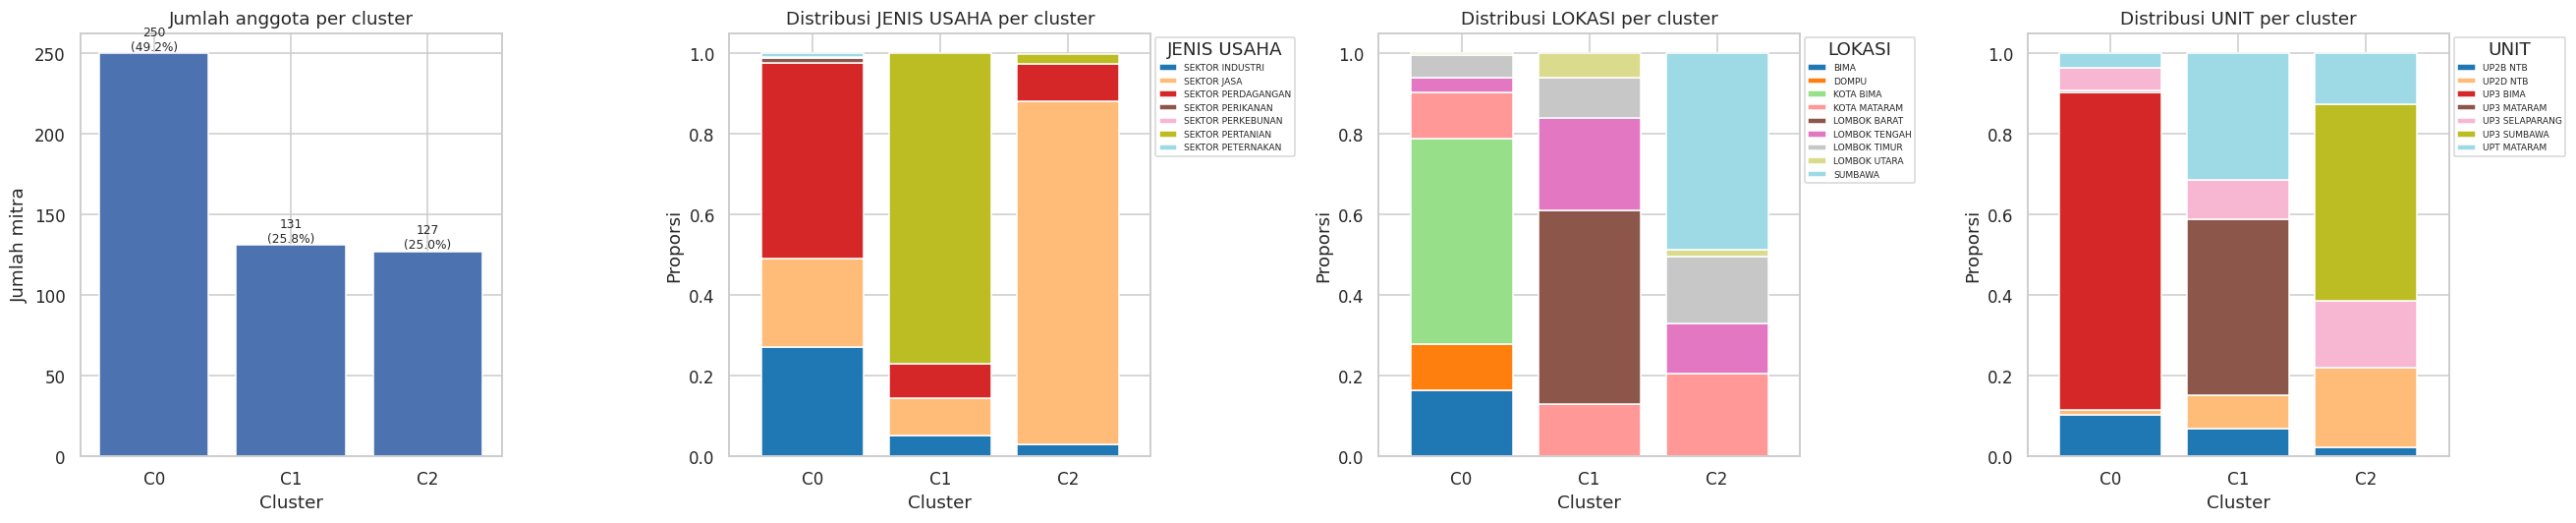

In [36]:
# Ukuran cluster dan komposisi tiap fitur per cluster
nama_c = ringkasan_cluster["nama_deskriptif"].to_dict()
fig, ax = plt.subplots(1, 4, figsize=(24, 5))
ax[0].bar([f"C{i}" for i in ukuran.index], ukuran.values, color="#4C72B0")
for i, (v, p) in enumerate(zip(ukuran.values, ringkasan_cluster["persen"])): ax[0].text(i, v, f"{v}\n({p}%)", ha="center", va="bottom", fontsize=8)
ax[0].set_title("Jumlah anggota per cluster"); ax[0].set_xlabel("Cluster"); ax[0].set_ylabel("Jumlah mitra")
for a, c in zip(ax[1:], FITUR_CLUSTER):
    (profil_tabel[c] / 100).rename(index=lambda i: f"C{i}").plot(kind="bar", stacked=True, ax=a, colormap="tab20", width=0.8)
    a.set_title(f"Distribusi {c} per cluster"); a.set_xlabel("Cluster"); a.set_ylabel("Proporsi"); a.legend(fontsize=6, title=c, bbox_to_anchor=(1, 1))
    plt.setp(a.get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

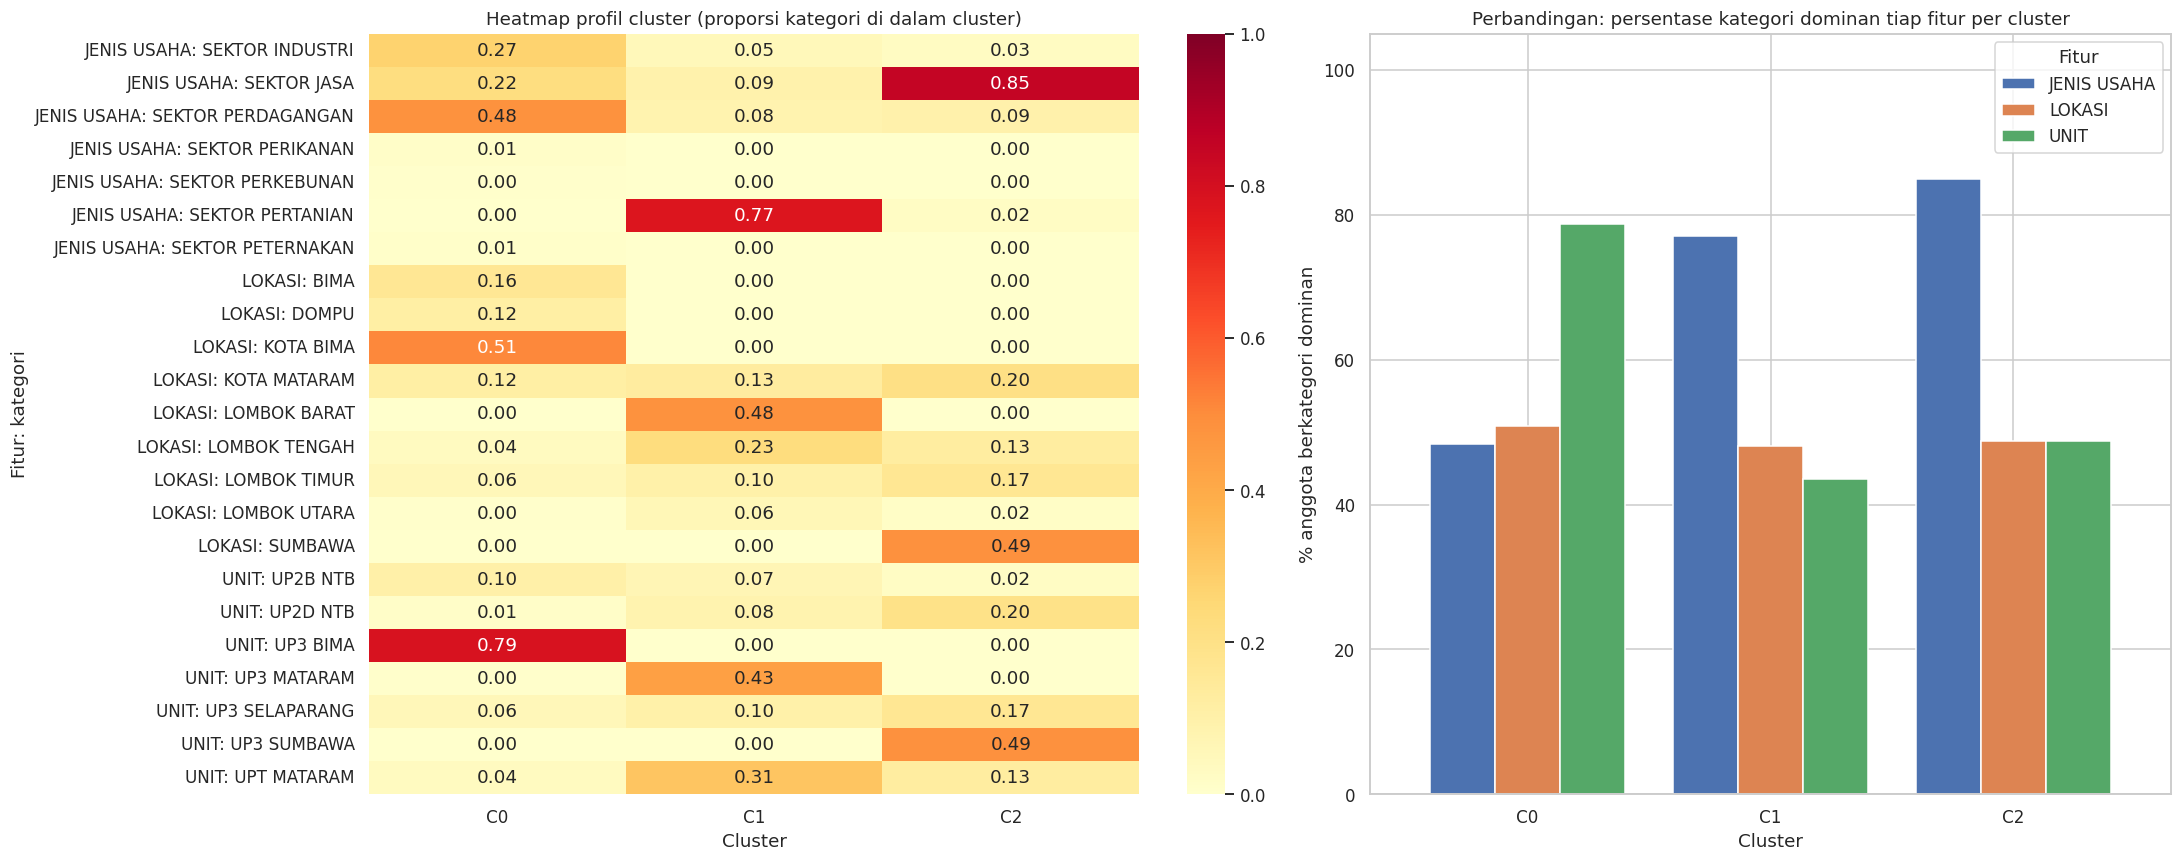

In [37]:
# Heatmap profil (proporsi tiap kategori di dalam cluster) dan perbandingan kekuatan ciri dominan antar cluster
gabung = pd.concat({c: profil_tabel[c].T for c in FITUR_CLUSTER}).droplevel(0, axis=0) / 100
gabung.index = [f"{c}: {k}" for c in FITUR_CLUSTER for k in profil_tabel[c].columns]
gabung.columns = [f"C{i}" for i in gabung.columns]
fig, ax = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(gabung, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=ax[0])
ax[0].set_title("Heatmap profil cluster (proporsi kategori di dalam cluster)"); ax[0].set_xlabel("Cluster"); ax[0].set_ylabel("Fitur: kategori")
share_dom = ringkasan_cluster[[f"{c}_%dominan" for c in FITUR_CLUSTER]]
share_dom.columns = FITUR_CLUSTER; share_dom.index = [f"C{i}" for i in share_dom.index]
share_dom.plot(kind="bar", ax=ax[1], width=0.8); ax[1].set_ylim(0, 105)
ax[1].set_title("Perbandingan: persentase kategori dominan tiap fitur per cluster"); ax[1].set_xlabel("Cluster"); ax[1].set_ylabel("% anggota berkategori dominan"); ax[1].legend(title="Fitur")
plt.setp(ax[1].get_xticklabels(), rotation=0); plt.tight_layout(); plt.show()

,n,sil_rata,n_negatif,n_rendah,n_baik,%_negatif
CLUSTER,,,,,,
0,250,0.354,16,55,179,6.4
1,131,0.330,2,52,77,1.5
2,127,0.374,0,34,93,0.0


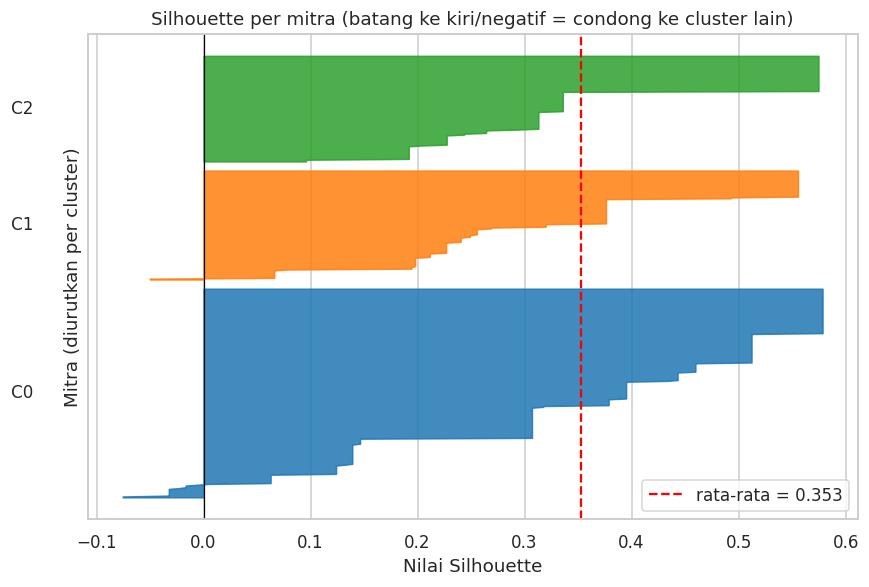

In [38]:
# Silhouette tiap mitra: positif = cocok dengan clusternya, negatif = lebih dekat ke cluster lain
from sklearn.metrics import silhouette_samples
WARNA = dict(zip(sorted(df_hasil["CLUSTER"].unique()), sns.color_palette("tab10", df_hasil["CLUSTER"].nunique())))

sil_i = silhouette_samples(D, label_final, metric="precomputed")
df_hasil["SIL"] = sil_i
ringkas_sil = df_hasil.groupby("CLUSTER")["SIL"].agg(
    n="size", sil_rata="mean", n_negatif=lambda s: int((s < 0).sum()),
    n_rendah=lambda s: int(((s >= 0) & (s < 0.25)).sum()), n_baik=lambda s: int((s >= 0.25).sum()))
ringkas_sil["%_negatif"] = (ringkas_sil["n_negatif"] / ringkas_sil["n"] * 100).round(1)
display(ringkas_sil.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5)); y0 = 0
for cl in sorted(WARNA):
    s = np.sort(sil_i[label_final == cl]); y1 = y0 + len(s)
    ax.fill_betweenx(np.arange(y0, y1), 0, s, color=WARNA[cl], alpha=0.85)
    ax.text(-0.18, y0 + len(s) / 2, f"C{cl}", fontsize=11, va="center"); y0 = y1 + 10
ax.axvline(sil_i.mean(), color="red", ls="--", label=f"rata-rata = {sil_i.mean():.3f}"); ax.axvline(0, color="black", lw=0.8)
ax.set_title("Silhouette per mitra (batang ke kiri/negatif = condong ke cluster lain)")
ax.set_xlabel("Nilai Silhouette"); ax.set_ylabel("Mitra (diurutkan per cluster)"); ax.set_yticks([]); ax.legend()
plt.tight_layout(); plt.show()

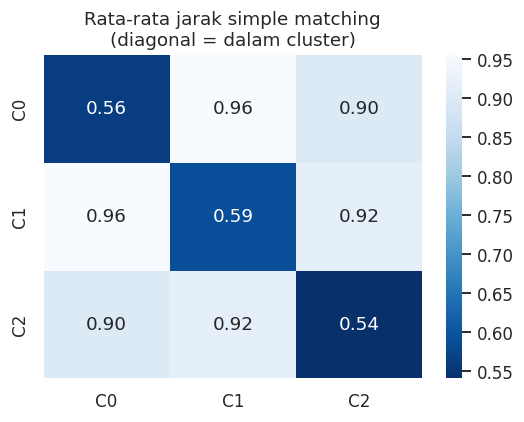

MARGIN,0 seri,1 tipis,2 cukup jelas,3 sangat jelas,All
CLUSTER,,,,,
0,26,113,57,54,250
1,2,92,5,32,131
2,0,80,4,43,127
All,28,285,66,129,508


,% mitra
MARGIN,
0 seri,5.5
1 tipis,56.1
2 cukup jelas,13.0
3 sangat jelas,25.4


In [39]:
# Rata-rata jarak antar anggota: diagonal = dalam cluster (kecil = rapat), di luar diagonal = antar cluster (besar = terpisah)
K = sorted(df_hasil["CLUSTER"].unique())
jarak_antar = pd.DataFrame([[D[np.ix_(label_final == a, label_final == b)].mean() for b in K] for a in K],
                           index=[f"C{k}" for k in K], columns=[f"C{k}" for k in K])
plt.figure(figsize=(5, 4)); sns.heatmap(jarak_antar, annot=True, fmt=".2f", cmap="Blues_r")
plt.title("Rata-rata jarak simple matching\n(diagonal = dalam cluster)"); plt.tight_layout(); plt.show()

# Margin = selisih jarak ke pusat terdekat vs pusat kedua terdekat (0 = seri, makin besar makin jelas)
modus = {cl: {f: g[f].value_counts().index[0] for f in FITUR_CLUSTER} for cl, g in df_hasil.groupby("CLUSTER")}
J = np.column_stack([sum((df_hasil[f] != modus[cl][f]).astype(int) for f in FITUR_CLUSTER) for cl in K])
js = np.sort(J, axis=1); df_hasil["MARGIN"] = js[:, 1] - js[:, 0]
ket = {0: "0 seri", 1: "1 tipis", 2: "2 cukup jelas", 3: "3 sangat jelas"}
tab_margin = pd.crosstab(df_hasil["CLUSTER"], df_hasil["MARGIN"].map(ket), margins=True)
display(tab_margin)
display((df_hasil["MARGIN"].map(ket).value_counts(normalize=True).sort_index() * 100).round(1).rename("% mitra").to_frame())

Korelasi jarak asli vs jarak di peta 2D = 0.60


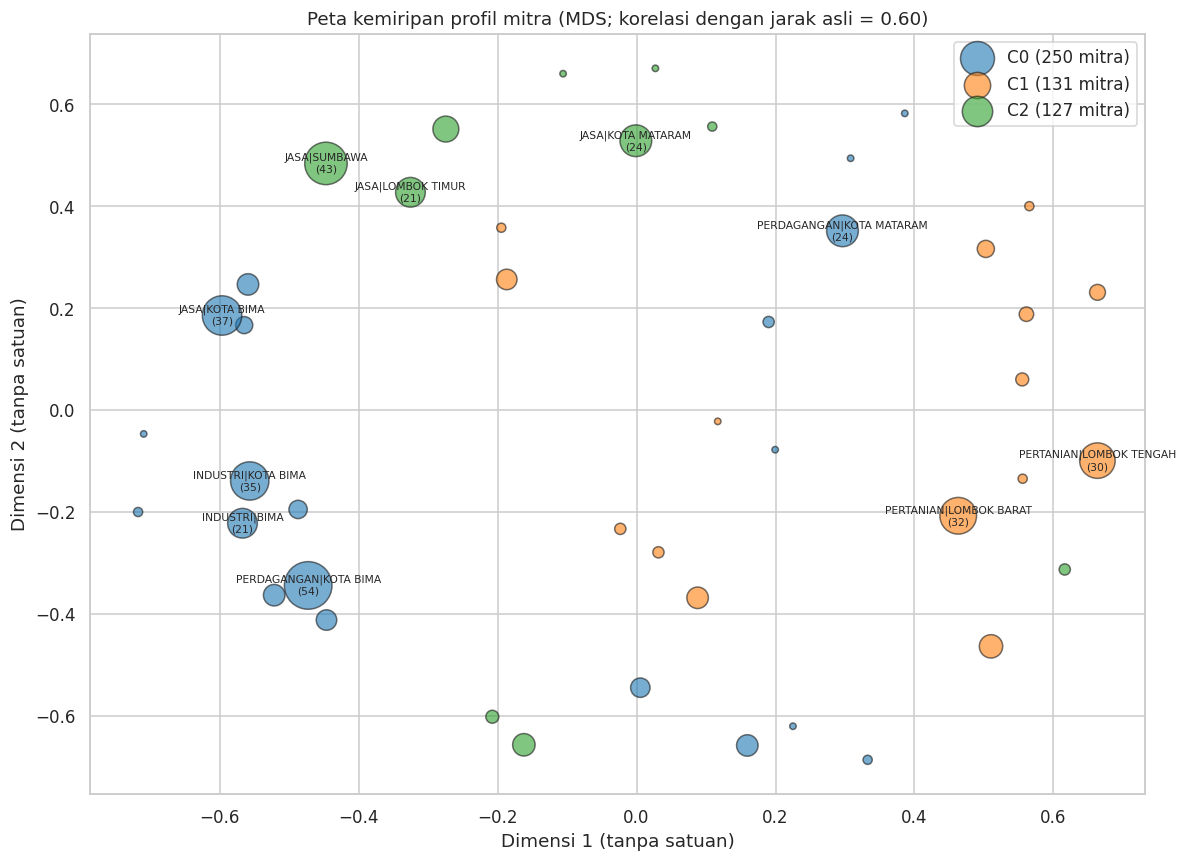

In [40]:
# MDS 2D dari jarak simple matching antar PROFIL unik (45 titik). Ukuran bubble = jumlah mitra pada profil itu.
from sklearn.manifold import MDS
prof = df_hasil.groupby(FITUR_CLUSTER).agg(n=("CLUSTER", "size"), CLUSTER=("CLUSTER", lambda s: s.value_counts().index[0])).reset_index()
Dp = pairwise_distances(OrdinalEncoder().fit_transform(prof[FITUR_CLUSTER]), metric="hamming")
Z = MDS(n_components=2, dissimilarity="precomputed", random_state=42, n_init=8).fit_transform(Dp)
iu = np.triu_indices(len(prof), 1)
kor = np.corrcoef(Dp[iu], pairwise_distances(Z)[iu])[0, 1]      # seberapa setia peta 2D terhadap jarak asli
print(f"Korelasi jarak asli vs jarak di peta 2D = {kor:.2f}")

fig, ax = plt.subplots(figsize=(11, 8))
for cl in K:
    m = (prof["CLUSTER"] == cl).values
    ax.scatter(Z[m, 0], Z[m, 1], s=prof.loc[m, "n"] * 18, color=WARNA[cl], alpha=0.6, edgecolor="k",
               label=f"C{cl} ({int(prof.loc[m, 'n'].sum())} mitra)")
for i, r in prof[prof["n"] >= 20].iterrows():
    ax.annotate(f"{r['JENIS USAHA'].replace('SEKTOR ', '')}|{r['LOKASI']}\n({r['n']})", (Z[i, 0], Z[i, 1]), fontsize=7, ha="center", va="center")
ax.set_title(f"Peta kemiripan profil mitra (MDS; korelasi dengan jarak asli = {kor:.2f})")
ax.set_xlabel("Dimensi 1 (tanpa satuan)"); ax.set_ylabel("Dimensi 2 (tanpa satuan)"); ax.legend()
plt.tight_layout(); plt.show()

% mitra terdekat ke pusat clusternya sendiri (peta 2D): {0: 89.6, 1: 90.1, 2: 86.6}


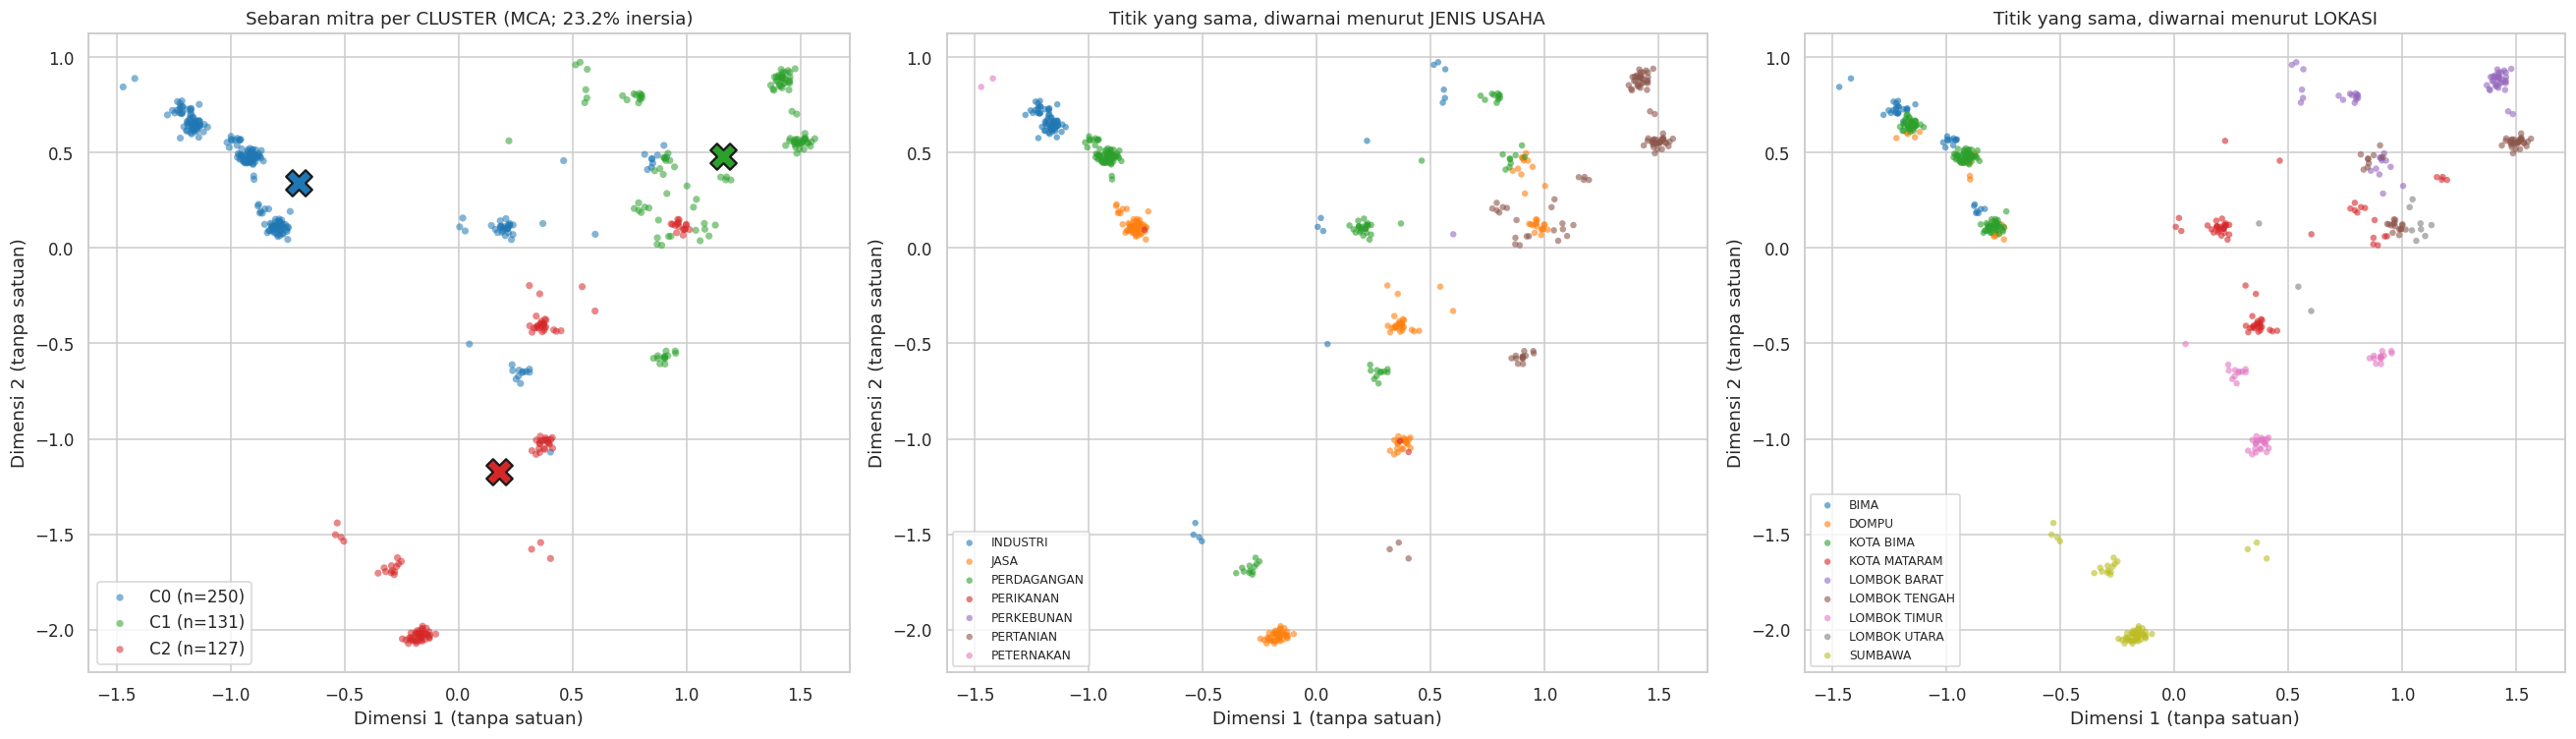

In [41]:
# Peta sebaran per mitra dengan MCA (Multiple Correspondence Analysis): padanan PCA untuk data kategorikal.
# Mitra dengan kategori mirip akan berdekatan. Ini hanya untuk visualisasi, bukan untuk membentuk cluster.
K = sorted(df_hasil["CLUSTER"].unique())
WARNA = dict(zip(K, ["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e", "#9467bd"][:len(K)]))
assert (df_hasil.index == np.arange(len(df_hasil))).all()          # indeks harus 0..n-1 agar sejajar dengan koordinat

# Hitung koordinat MCA dari tabel indikator kategori (one-hot hanya untuk plot ini)
Zind = pd.get_dummies(df_hasil[FITUR_CLUSTER].astype(str)).to_numpy(dtype=float)
P = Zind / Zind.sum()
r = P.sum(axis=1, keepdims=True); c = P.sum(axis=0, keepdims=True)
S = (P - r @ c) / np.sqrt(r) / np.sqrt(c)
U, sv, Vt = np.linalg.svd(S, full_matrices=False)
F = (U * sv) / np.sqrt(r)                                           # koordinat tiap mitra
inersia = sv ** 2 / (sv ** 2).sum()

# Mitra dengan profil identik jatuh di titik yang sama, jadi diberi jitter kecil agar jumlahnya terlihat
rng = np.random.default_rng(42)
xy = F[:, :2] + rng.normal(0, 1, (len(F), 2)) * F[:, :2].std(axis=0) * 0.03

# Cek kasar: berapa % mitra yang paling dekat ke pusat clusternya sendiri pada peta 2D
pusat = {cl: F[label_final == cl, :2].mean(axis=0) for cl in K}
dekat = np.array([min(K, key=lambda cl: np.linalg.norm(F[i, :2] - pusat[cl])) for i in range(len(F))])
print("% mitra terdekat ke pusat clusternya sendiri (peta 2D):",
      pd.Series(dekat == label_final).groupby(label_final).mean().mul(100).round(1).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(24, 7))
for cl in K:
    m = label_final == cl
    ax[0].scatter(xy[m, 0], xy[m, 1], s=22, alpha=0.55, color=WARNA[cl], label=f"C{cl} (n={m.sum()})", edgecolor="none")
    ax[0].scatter(*pusat[cl], s=300, marker="X", color=WARNA[cl], edgecolor="k", linewidth=1.5, zorder=5)
ax[0].set_title(f"Sebaran mitra per CLUSTER (MCA; {inersia[:2].sum()*100:.1f}% inersia)"); ax[0].legend()

# Dua panel pembantu: titik yang SAMA diwarnai menurut jenis usaha dan lokasi, untuk membaca arti letak titik
for a, f in zip(ax[1:], ["JENIS USAHA", "LOKASI"]):
    for i, (kat, g) in enumerate(df_hasil.groupby(f)):
        a.scatter(xy[g.index, 0], xy[g.index, 1], s=18, alpha=0.6, label=kat.replace("SEKTOR ", ""),
                  color=sns.color_palette("tab10", 10)[i], edgecolor="none")
    a.set_title(f"Titik yang sama, diwarnai menurut {f}"); a.legend(fontsize=8)
for a in ax: a.set_xlabel("Dimensi 1 (tanpa satuan)"); a.set_ylabel("Dimensi 2 (tanpa satuan)")
plt.tight_layout(); plt.show()

In [44]:
# Skala dominasi: % anggota cluster yang memiliki kategori terbanyak pada suatu fitur
def kelas_dominasi(p):
    if p >= 75: return "sangat dominan"
    if p >= 50: return "dominan"
    if p >= 25: return "cukup menonjol"
    return "tersebar"
def fmt(x): return f"{x:.1f}".replace(".", ",")

# Satu baris ringkasan per cluster. lift = porsi kategori di cluster / porsi kategori di seluruh data
def karakteristik_cluster(df, fitur=FITUR_CLUSTER, batas_nama=50):
    porsi_total = {f: df[f].value_counts(normalize=True) * 100 for f in fitur}
    baris = []
    for cl, g in df.groupby("CLUSTER"):
        info, kuat, kuat_nama, lemah = {}, {}, [], []
        for f in fitur:
            vc = g[f].value_counts(normalize=True) * 100
            top, p = vc.index[0], vc.iloc[0]
            kedua = f"; kedua: {vc.index[1]} ({fmt(vc.iloc[1])}%)" if len(vc) > 1 and vc.iloc[1] >= 15 else ""
            info[f] = f"{top} {fmt(p)}% [{kelas_dominasi(p)}, lift {fmt(p / porsi_total[f][top])}x]{kedua}"
            kuat[f] = p
            (kuat_nama if p >= batas_nama else lemah).append(top if p >= batas_nama else f)
        pembeda = max(kuat, key=kuat.get)
        nama = ", ".join(kuat_nama) if kuat_nama else "CAMPURAN"
        if lemah and kuat_nama: nama += f" ({', '.join(lemah)} menyebar)"
        baris.append({"CLUSTER": cl, "n": len(g), "%": round(len(g) / len(df) * 100, 1), **info,
                      "fitur_pembeda_utama": f"{pembeda} ({fmt(kuat[pembeda])}%)", "nama_cluster": f"C{cl}: {nama}"})
    return pd.DataFrame(baris).set_index("CLUSTER")

tabel_karakter = karakteristik_cluster(df_hasil)
for cl, r in tabel_karakter.iterrows():
    print(f"\n{r['nama_cluster']}  |  {r['n']} mitra ({fmt(r['%'])}%)")
    for f in FITUR_CLUSTER: print(f"   - {f:12s}: {r[f]}")
    print(f"   - pembeda utama: {r['fitur_pembeda_utama']}")


C0: KOTA BIMA, UP3 BIMA (JENIS USAHA menyebar)  |  250 mitra (49,2%)
   - JENIS USAHA : SEKTOR PERDAGANGAN 48,4% [cukup menonjol, lift 1,7x]; kedua: SEKTOR INDUSTRI (27,2%)
   - LOKASI      : KOTA BIMA 50,8% [dominan, lift 2,0x]; kedua: BIMA (16,4%)
   - UNIT        : UP3 BIMA 78,8% [sangat dominan, lift 2,0x]
   - pembeda utama: UNIT (78,8%)

C1: SEKTOR PERTANIAN (LOKASI, UNIT menyebar)  |  131 mitra (25,8%)
   - JENIS USAHA : SEKTOR PERTANIAN 77,1% [sangat dominan, lift 3,8x]
   - LOKASI      : LOMBOK BARAT 48,1% [cukup menonjol, lift 3,9x]; kedua: LOMBOK TENGAH (22,9%)
   - UNIT        : UP3 MATARAM 43,5% [cukup menonjol, lift 3,8x]; kedua: UPT MATARAM (31,3%)
   - pembeda utama: JENIS USAHA (77,1%)

C2: SEKTOR JASA (LOKASI, UNIT menyebar)  |  127 mitra (25,0%)
   - JENIS USAHA : SEKTOR JASA 85,0% [sangat dominan, lift 2,5x]
   - LOKASI      : SUMBAWA 48,8% [cukup menonjol, lift 4,0x]; kedua: KOTA MATARAM (20,5%)
   - UNIT        : UP3 SUMBAWA 48,8% [cukup menonjol, lift 4,0x]; ked

In [45]:
# Hitung mode tiap cluster, cost per cluster, dan jarak tiap profil ke setiap mode
modus = {cl: {f: g[f].value_counts().index[0] for f in FITUR_CLUSTER} for cl, g in df_hasil.groupby("CLUSTER")}
cost_rows = []
for cl, g in df_hasil.groupby("CLUSTER"):
    r = {"CLUSTER": cl, "n": len(g), **{f"{f}_beda": int((g[f] != modus[cl][f]).sum()) for f in FITUR_CLUSTER}}
    r["cost_cluster"] = sum(r[f"{f}_beda"] for f in FITUR_CLUSTER); cost_rows.append(r)
tabel_cost = pd.DataFrame(cost_rows); display(pd.DataFrame(modus).T); display(tabel_cost)
print("Total cost manual =", tabel_cost["cost_cluster"].sum(), "| cost model =", row_final["cost"])

profil = df_hasil.groupby(FITUR_CLUSTER).agg(n=("CLUSTER", "size"), label=("CLUSTER", lambda s: s.value_counts().index[0])).reset_index()
for cl in modus: profil[f"jarak_C{cl}"] = sum((profil[f] != modus[cl][f]).astype(int) for f in FITUR_CLUSTER)
kol_j = [f"jarak_C{cl}" for cl in modus]
profil["terdekat"] = profil[kol_j].values.argmin(axis=1)
print("Kecocokan label dengan pusat terdekat:", (profil["terdekat"] == profil["label"]).mean())
display(profil.sort_values("n", ascending=False).head(12))

,JENIS USAHA,LOKASI,UNIT
0,SEKTOR PERDAGANGAN,KOTA BIMA,UP3 BIMA
1,SEKTOR PERTANIAN,LOMBOK BARAT,UP3 MATARAM
2,SEKTOR JASA,SUMBAWA,UP3 SUMBAWA


,CLUSTER,n,JENIS USAHA_beda,LOKASI_beda,UNIT_beda,cost_cluster
0,0,250,129,123,53,305
1,1,131,30,68,74,172
2,2,127,19,65,65,149


Total cost manual = 626 | cost model = 626.0
Kecocokan label dengan pusat terdekat: 1.0


,JENIS USAHA,LOKASI,UNIT,n,label,jarak_C0,jarak_C1,jarak_C2,terdekat
23,SEKTOR PERDAGANGAN,KOTA BIMA,UP3 BIMA,54,0,0,3,3,0
20,SEKTOR JASA,SUMBAWA,UP3 SUMBAWA,43,2,3,3,0,2
11,SEKTOR JASA,KOTA BIMA,UP3 BIMA,37,0,1,3,2,0
2,SEKTOR INDUSTRI,KOTA BIMA,UP3 BIMA,35,0,1,3,3,0
37,SEKTOR PERTANIAN,LOMBOK BARAT,UP3 MATARAM,32,1,3,0,3,1
39,SEKTOR PERTANIAN,LOMBOK TENGAH,UPT MATARAM,30,1,3,2,3,1
24,SEKTOR PERDAGANGAN,KOTA MATARAM,UP2B NTB,24,0,2,3,3,0
13,SEKTOR JASA,KOTA MATARAM,UP2D NTB,24,2,3,3,2,2
17,SEKTOR JASA,LOMBOK TIMUR,UP3 SELAPARANG,21,2,3,3,2,2
0,SEKTOR INDUSTRI,BIMA,UP3 BIMA,21,0,2,3,3,0


## 14. Kesimpulan dan Interpretasi
Ringkasan di bawah dibangkitkan dari hasil perhitungan aktual. Narasi substantif ditulis ulang di laporan setelah membaca tabel-tabel sebelumnya.

In [42]:
# Ringkasan hasil dari variabel hasil perhitungan (tidak ada angka yang ditulis manual)
puncak_th = int(tren_tahun["jumlah_mitra"].idxmax())
ringkasan_teks = [
    ("Jumlah mitra analisis", len(df_clean)),
    ("Rentang tahun salur", f"{th_min}-{th_max}"),
    ("Tahun tanpa observasi dalam rentang", f"{tahun_tanpa_data[0]}-{tahun_tanpa_data[-1]} ({len(tahun_tanpa_data)} tahun)" if tahun_tanpa_data else "tidak ada"),
    ("Tahun penyaluran terbanyak", f"{puncak_th} ({int(tren_tahun.loc[puncak_th,'jumlah_mitra'])} mitra)"),
    ("Jenis usaha dominan", f"{tren_jenis_total.index[0]} ({tren_jenis_total.iloc[0,1]}%)"),
    ("Lokasi dominan", f"{tren_lokasi_total.index[0]} ({tren_lokasi_total.iloc[0,1]}%)"),
    ("Unit dominan", f"{tren_unit_total.index[0]} ({tren_unit_total.iloc[0,1]}%)"),
    ("Asosiasi LOKASI-UNIT (Cramér's V)", round(V.loc["LOKASI", "UNIT"], 2)),
    ("Jumlah profil unik 3 fitur", n_profil_unik),
    ("Metode inisialisasi terpilih", init_final), ("Jumlah cluster terpilih (K)", k_final),
    ("Seed representatif", seed_final), ("n_init / max_iter", f"{N_INIT if init_final!='Cao' else 1} / {MAX_ITER}"),
    ("Silhouette (simple matching)", round(float(row_final["silhouette"]), 4)), ("Cost K-Modes", round(float(row_final["cost"]), 1)),
    ("ARI antar-seed (konfigurasi terpilih)", round(float(agg[(agg['init'] == init_final) & (agg['k'] == k_final)]['ari_rata'].iloc[0]), 3)),
    ("Ukuran cluster", row_final["ukuran_cluster"]),
]
df_ringkasan = pd.DataFrame(ringkasan_teks, columns=["item", "nilai"]).astype({"nilai": str})
display(df_ringkasan)
for i, r in ringkasan_cluster.iterrows(): print(f"Cluster {i}: {r['n_mitra']} mitra ({r['persen']}%) -> {r['nama_deskriptif']}")
print("\nKeterbatasan yang wajib dicantumkan di laporan: (1) redundansi LOKASI-UNIT; (2) tahun tanpa data tidak dianggap nol; (3) tren hanya untuk mitra yang tercatat; (4) segmentasi hanya mencerminkan 3 fitur kategorikal.")

,item,nilai
0,Jumlah mitra analisis,508
1,Rentang tahun salur,1993-2020
2,Tahun tanpa observasi dalam rentang,2012-2017 (6 tahun)
3,Tahun penyaluran terbanyak,1996 (162 mitra)
4,Jenis usaha dominan,SEKTOR JASA (34.4%)
5,Lokasi dominan,KOTA BIMA (25.0%)
6,Unit dominan,UP3 BIMA (38.8%)
7,Asosiasi LOKASI-UNIT (Cramér's V),0.88
8,Jumlah profil unik 3 fitur,45
9,Metode inisialisasi terpilih,Random


Cluster 0: 250 mitra (49.2%) -> C0: SEKTOR PERDAGANGAN | KOTA BIMA | UP3 BIMA
Cluster 1: 131 mitra (25.8%) -> C1: SEKTOR PERTANIAN | LOMBOK BARAT | UP3 MATARAM
Cluster 2: 127 mitra (25.0%) -> C2: SEKTOR JASA | SUMBAWA | UP3 SUMBAWA

Keterbatasan yang wajib dicantumkan di laporan: (1) redundansi LOKASI-UNIT; (2) tahun tanpa data tidak dianggap nol; (3) tren hanya untuk mitra yang tercatat; (4) segmentasi hanya mencerminkan 3 fitur kategorikal.


## 15. Export Hasil
Hasil disimpan dalam satu file Excel. Kolom identitas: `NO ID` disertakan pada hasil cluster sebagai kunci; `NAMA USAHA` **tidak** diekspor secara default (ubah `SERTAKAN_NAMA_USAHA` bila memang perlu).

In [43]:
# Simpan seluruh hasil ke Excel (data mentah asli tidak diubah)
SERTAKAN_NAMA_USAHA = False
data_clean_export = df_clean.copy()
for c in FITUR_CLUSTER: data_clean_export[c] = data_clean_export[c].astype(str)
if not SERTAKAN_NAMA_USAHA: data_clean_export = data_clean_export.drop(columns=["NAMA USAHA"])

path_xlsx = os.path.join(OUT_DIR, "Hasil_Analisis_PUMK_KModes.xlsx")
with pd.ExcelWriter(path_xlsx, engine="openpyxl") as w:
    data_clean_export.to_excel(w, sheet_name="Data_Clean", index=False)
    pd.DataFrame(log_cleaning).to_excel(w, sheet_name="Log_Cleaning", index=False)
    tren_tahun.reset_index().rename(columns={"TAHUN SALUR": "tahun_salur"}).to_excel(w, sheet_name="Tren_Tahun", index=False)
    tren_jenis_periode.reset_index().to_excel(w, sheet_name="Tren_Jenis_Periode", index=False)
    tren_lokasi_periode.reset_index().to_excel(w, sheet_name="Tren_Lokasi_Periode", index=False)
    tren_unit_periode.reset_index().to_excel(w, sheet_name="Tren_Unit_Periode", index=False)
    df_exp.assign(ukuran_cluster=df_exp["ukuran_cluster"].astype(str)).to_excel(w, sheet_name="Eksperimen_KModes", index=False)
    tabel_model.to_excel(w, sheet_name="Evaluasi_Model", index=False)
    antar_init.reset_index().to_excel(w, sheet_name="ARI_Antar_Init", index=False)
    sens_ringkas.reset_index().to_excel(w, sheet_name="Sensitivitas_Parameter", index=False)
    df_hasil.to_excel(w, sheet_name="Hasil_Cluster", index=False)
    ringkasan_cluster.reset_index().to_excel(w, sheet_name="Profil_Cluster", index=False)
    df_ringkasan.to_excel(w, sheet_name="Ringkasan", index=False)
print("Tersimpan:", path_xlsx)
if IN_COLAB:
    from google.colab import files
    files.download(path_xlsx)
# Notebook .ipynb disimpan lewat menu Colab: File > Save a copy / Download .ipynb

Tersimpan: /content/hasil_pumk/Hasil_Analisis_PUMK_KModes.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>